# **Entendimiento del negocio**
---


In [2]:
# ============================================================
# CONFIGURACIÓN DE DIAGRAMAS
# Ejecute esta celda antes de generar los diagramas del documento.
#  - mermaid(): dibuja diagramas Mermaid con el servicio mermaid.ink
#  - diagrams: dibuja la arquitectura con íconos (requiere Graphviz)
# ============================================================
!pip install -q diagrams
!apt-get -qq install -y graphviz > /dev/null

import base64
from IPython.display import Image, display

def mermaid(codigo):
    b64 = base64.urlsafe_b64encode(codigo.encode("utf-8")).decode("ascii")
    display(Image(url="https://mermaid.ink/img/" + b64))

ESTILO_MERMAID = """%%{init: {
  "theme": "base",
  "flowchart": {"curve": "basis", "nodeSpacing": 40, "rankSpacing": 60, "padding": 20, "htmlLabels": true},
  "themeVariables": {
    "fontFamily": "Helvetica, Arial, sans-serif", "fontSize": "14px",
    "lineColor": "#94A3B8", "primaryBorderColor": "#CBD5E1",
    "clusterBkg": "#F8FAFC", "clusterBorder": "#E2E8F0"
  }
}}%%
"""

zsh:1: command not found: apt-get


## **Dos conteos, dos elecciones**
### Plataforma de big data para analizar la concordancia del conteo y la correspondencia territorial del voto en Colombia 2026

---

## **1. Marco de Proyecto**
---

Normalmente, se suele construir un marco de proyecto para mostrar los resultados del entendimiento del negocio, es decir, debemos dar respuesta a los siguientes elementos:

### **1.1. Trasfondo del Negocio**
---
- ¿Quienes son los beneficiarios del proyecto? ¿En qué dominio se encuentran (marketing, medicina, entre otros)?
- ¿Cuáles son los principales desafíos o problemas de la situación que motivan la necesidad de realizar un proyecto de análisis de datos?

#### ¿Quiénes son los beneficiarios del proyecto? ¿En qué dominio se encuentran?

**Dominio:** gobierno, transparencia electoral y datos abiertos (*civic tech*), en la intersección con la ciencia política aplicada.

**Beneficiarios:**

| Beneficiario | Necesidad que atiende el proyecto |
|---|---|
| **Organizaciones de observación electoral** (p. ej. la Misión de Observación Electoral – MOE) | Contar con un análisis territorial independiente del comportamiento del voto y de los lugares donde se concentran las correcciones entre preconteo y escrutinio, para contrastarlo con lo que observan en campo. |
| **Academia e investigadores en ciencia política** | Analizar con datos cómo se relaciona el voto al Congreso con el voto presidencial en el territorio, y si la complejidad del tarjetón afecta la calidad del conteo, a una escala que hoy exige un procesamiento que pocos pueden hacer. |
| **Periodistas de datos y medios** | Consultar de forma rápida y verificable los resultados, las correcciones y las diferencias por candidato, partido o municipio. |
| **Partidos y campañas** | Entender la base territorial de su votación y dónde su voto presidencial y su voto congresional coinciden o se separan. |
| **Autoridad electoral** (beneficiario indirecto) | Identificar en qué corporaciones y territorios se concentran las correcciones del conteo, como insumo para la capacitación de jurados. |
| **Equipos técnicos de datos** (observatorios, universidades, medios) | Saber, con evidencia, qué tecnología conviene para cada tipo de consulta y desde qué volumen se justifica el procesamiento distribuido. |
| **Ciudadanía** | Consultar los resultados de su puesto o municipio de forma sencilla. |

#### ¿Cuáles son los principales desafíos o problemas que motivan el proyecto?

**Contexto.** En 2026 Colombia tuvo tres elecciones nacionales: Congreso (8 de marzo), primera vuelta presidencial (31 de mayo) y segunda vuelta (21 de junio). Las mismas personas, en los mismos puestos de votación, eligieron con menos de tres meses de diferencia a sus congresistas y a su presidente.

De cada elección, la Registraduría publica los resultados mesa a mesa en archivos abiertos, en dos versiones:

- el **preconteo**, que es el conteo de los jurados la noche de la elección;
- el **escrutinio**, que es el resultado oficial.

Con estos datos se puede estudiar con detalle territorial dos cosas: si el electorado distribuye su voto de forma parecida entre una elección y otra, y qué tanto coinciden los dos conteos de un mismo voto.

Los principales problemas que motivan el proyecto son:

1. **No se sabe qué listas al Senado y qué candidatos presidenciales tienen su fuerza en los mismos territorios.** En 2026, el mismo electorado votó por el Congreso en marzo y por la Presidencia en mayo, lo que permite comparar en qué lugares se concentró cada apoyo. Hoy esa relación se analiza con resultados agregados por departamento, que mezclan territorios que votan de forma muy distinta, o con encuestas, que consultan a pocas personas y no muestran qué ocurrió en cada lugar. Aunque los resultados de cada puesto de votación son públicos, no existe una medición sistemática que los use para establecer qué listas y qué candidatos comparten base territorial.

2. **No se identifica dónde el voto presidencial se aparta del congresional.** Sin esa información, partidos, analistas y observadores no pueden distinguir los territorios donde el voto sigue la lógica de partido de aquellos donde es un voto personal por el candidato.

3. **No se sabe en qué lugares ni en qué tipo de elección se corrigen más los votos entre el preconteo y el escrutinio.** Cada voto se cuenta dos veces: primero los jurados en la mesa, la noche de la elección (preconteo), y después las comisiones escrutadoras, que revisan las actas y fijan el resultado oficial (escrutinio). La Registraduría informa qué tanto coinciden los dos conteos a nivel nacional, pero esa cifra no muestra en qué municipios o puestos se concentran las correcciones, ni si son más frecuentes en los tarjetones más difíciles de contar, como el del Senado con voto preferente frente al presidencial. Sin esa información no es posible distinguir las correcciones habituales de las concentraciones atípicas, ni orientar la capacitación de jurados hacia donde más se necesita.

4. **Las conclusiones sobre el comportamiento electoral se basan en intuición o en encuestas.** Los resultados reales por puesto de votación están disponibles, pero no se usan de forma sistemática para contrastar esas interpretaciones con evidencia.

5. **Los datos son abiertos, pero en la práctica no son accesibles.** La Registraduría publica todos los resultados mesa a mesa, pero:
   - en formatos técnicos (ancho fijo y CSV);
   - con llaves que no coinciden entre fuentes y códigos territoriales distintos a los del DANE;
   - con un volumen (≈ 10 GB y del orden de 180 millones de registros) que no se puede procesar con herramientas de uso común como Excel.

   Solo equipos con capacidad técnica especializada pueden aprovecharlos, lo que limita el análisis independiente de la ciudadanía, los medios y las organizaciones pequeñas. Además, no está claro desde qué volumen y para qué operaciones se justifica una arquitectura distribuida frente a una solución en una sola máquina.

#### Objetivo del negocio

Dar a los beneficiarios una herramienta confiable, rápida y reproducible para:

- consultar los resultados electorales de 2026 a nivel de puesto de votación;
- evaluar con evidencia la correspondencia territorial del voto entre elecciones y la concordancia entre los dos conteos.

#### Preguntas del proyecto

- **P1.** ¿En qué medida la distribución territorial del voto presidencial de 2026 corresponde a la del voto al Senado del mismo electorado, y en qué territorios se aparta?
- **P2.** ¿Las correcciones entre el preconteo y el escrutinio aumentan con la complejidad del tarjetón, y en qué territorios se concentran?
- **P3.** ¿Desde qué volumen de datos y para qué tipo de operaciones el procesamiento distribuido y el almacenamiento NoSQL superan a una solución de una sola máquina, y cómo se comparan el costo teórico y el medido?

#### Hipótesis

- **H1 (comportamiento del voto):** existen listas al Senado y candidatos presidenciales que comparten base territorial, y zonas identificables donde el voto presidencial se aparta de lo que predice la composición del voto al Senado en el mismo puesto.
- **H2 (proceso de conteo):** las correcciones entre preconteo y escrutinio son más frecuentes y más grandes cuanto más complejo es el tarjetón (Presidencia → Cámara → Senado con voto preferente).
- **H3 (arquitectura):** con el volumen de 2026, una solución de una sola máquina es competitiva para el procesamiento por lotes. El procesamiento distribuido gana a partir de un volumen que se puede estimar con el modelo de costos, y el almacenamiento precalculado mantiene una latencia de consulta estable que no depende del volumen.

Los resultados de P2 sirven además como **control de calidad** para P1: si las correcciones del conteo son pequeñas frente a los desvíos encontrados, los desvíos no se pueden atribuir a errores de conteo.

#### Objetivo del proyecto

**Objetivo general.** Implementar una arquitectura de big data (procesamiento distribuido, NoSQL documental y NoSQL columnar) que integre los resultados de Congreso y Presidencia 2026 a nivel de mesa y de puesto de votación. Con ella se busca:

- medir la correspondencia territorial del voto entre elecciones;
- medir la concordancia entre los dos conteos;
- ofrecer consultas de baja latencia sobre los resultados;
- evaluar con evidencia cuándo se justifica cada tecnología.

**Objetivos específicos.**

| # | Objetivo | Pregunta | Tecnología |
|---|---|---|---|
| OE1 | Construir un pipeline ETL distribuido que lea los archivos crudos (ancho fijo y CSV), normalice las llaves entre fuentes (zona, partido, corporación) y entre sistemas de códigos (Registraduría y DANE), y produzca Parquet curado a nivel de mesa y de puesto | Base de P1–P3 | Spark |
| OE2 | Identificar los puestos comparables entre elecciones (mismo nombre y electorado estable según el potencial de DIVIPOL) y documentar los criterios de exclusión | P1 | Spark |
| OE3 | Medir la correspondencia territorial del voto: calcular a partir de los datos la matriz de afinidad entre listas al Senado y candidatos presidenciales (correlación entre puestos, a nivel nacional y dentro de cada departamento) y la tabla de desvíos del voto presidencial por puesto (residuo de una regresión simple), y probar H1 | P1 | Spark + estadística |
| OE4 | Medir la concordancia entre conteos: calcular la corrección relativa entre preconteo y escrutinio por puesto y corporación, separando el traslado de votos de candidatos retirados, y probar H2 | P2 | Spark + estadística |
| OE5 | Ofrecer consultas de detalle por puesto y búsqueda de candidatos por nombre | P1, P2 | MongoDB |
| OE6 | Ofrecer consultas fijas a nivel de territorio y, para el Senado, a nivel de mesa (resultados, afinidad, desvíos y correcciones) con latencia p99 < 100 ms bajo carga concurrente | P1, P2 | Cassandra |
| OE7 | Medir la escalabilidad de Spark al variar el número de núcleos (*strong scaling*), compararla con una línea base de una sola máquina (DuckDB) y resolver las mismas consultas en Spark, DuckDB, MongoDB y Cassandra, contrastando los tiempos medidos con el costo teórico de cada operación, para probar H3 | P3 | Spark, DuckDB, MongoDB, Cassandra |

### **1.2. Alcance**
---

- ¿Qué  solución se desea implementar?
- ¿Cuáles son los límites y fronteras del proyecto de análisis de datos? ¿Qué aspectos específicos del negocio se incluirán y cuáles se excluyen en el alcance del proyecto?
- ¿De qué forma el cliente o beneficiario utilizará el producto del proyecto?

#### ¿Qué solución se desea implementar?

Una **plataforma analítica de big data** que integra los resultados de preconteo y escrutinio de las elecciones de Senado, Cámara y primera vuelta presidencial de 2026, y los lleva a una unidad territorial comparable: el puesto de votación. Sobre esa base, la plataforma:

1. **Procesa e integra los datos:** lee los archivos públicos de la Registraduría, los limpia, unifica sus llaves y códigos, y genera un conjunto de datos curado y reproducible.
2. **Analiza la correspondencia territorial del voto (P1):** mide qué listas al Senado y qué candidatos presidenciales comparten base territorial, con relaciones calculadas a partir de los datos y no asignadas de antemano, e identifica dónde el voto presidencial se aparta de la base congresional.
3. **Analiza la concordancia del conteo (P2):** mide las correcciones entre preconteo y escrutinio por puesto y corporación, e identifica si aumentan con la complejidad del tarjetón y en qué territorios se concentran.
4. **Evalúa su propio rendimiento (P3):** compara el procesamiento distribuido y las bases NoSQL con una solución de una sola máquina, para establecer con evidencia cuándo se justifica cada tecnología.
5. **Permite consultar los resultados:** ofrece búsquedas rápidas por candidato, partido, municipio o puesto, y el detalle de cada puesto en las dos elecciones y en los dos conteos.
6. **Presenta los hallazgos:** mediante un dashboard con tablas y gráficos, desde el que también se descargan los resultados.

El detalle de las tecnologías y de cómo se conectan los componentes se describe en la sección de diseño y arquitectura de la solución.

#### ¿Cuáles son los límites y fronteras del proyecto?

- **Fuentes de datos:** los archivos públicos de resultados mesa a mesa (MMV) de preconteo y escrutinio, y los archivos básicos (DIVIPOL, partidos, candidatos) que publica la Registraduría Nacional del Estado Civil. Además, los códigos DIVIPOLA del DANE, como tabla de referencia para normalizar los territorios. No se usan encuestas ni datos individuales de votantes.
- **Periodo:** elecciones de 2026; no se comparan con elecciones de años anteriores.
- **Elecciones según la pregunta:**
  - **P1:** Senado de la República (8 de marzo de 2026) frente a la primera vuelta presidencial (31 de mayo de 2026), con resultados de escrutinio.
  - **P2:** Presidencia, Cámara y Senado, comparando preconteo con escrutinio dentro de cada elección.
- **Territorio:** puestos de votación ubicados en Colombia.
- **Unidad de análisis:** el puesto de votación, que es el nivel más fino en el que el electorado es comparable entre las dos elecciones. También se agrega por municipio y departamento.
- **Tipo de análisis:** descriptivo y relacional (cómo se relaciona el voto entre elecciones en el territorio), con contraste de hipótesis (P2) y evaluación experimental de rendimiento (P3). No es predictivo ni causal.


#### ¿Qué aspectos se incluyen?

- Resultados de preconteo y escrutinio del **Senado, circunscripción nacional**.
- Resultados de preconteo y escrutinio de la **Cámara de Representantes**, solo para P2.
- Resultados de preconteo y escrutinio de la **primera vuelta presidencial**.
- Limpieza, normalización de llaves y códigos (Registraduría y DANE), e integración de las elecciones en un conjunto de datos curado.
- Selección de **puestos comparables** entre elecciones: mismo nombre y cambio en el potencial de votantes menor al 5 %.
- Agregación de resultados por puesto, municipio y departamento, con los nombres de la división territorial (DIVIPOL).
- Cálculo de la **afinidad territorial** entre listas al Senado (voto por la lista más votos preferentes de sus candidatos) y candidatos presidenciales.
- Identificación, en tablas por territorio, de los puestos donde el voto presidencial se aparta de la base congresional.
- Cálculo de las **correcciones entre preconteo y escrutinio** por puesto y corporación, separando el traslado de votos de candidatos retirados, y prueba de su relación con la complejidad del tarjetón.
- Consultas rápidas por candidato, partido, municipio o puesto, y detalle de cada puesto en ambas elecciones y ambos conteos.
- Dashboard para presentar y descargar los resultados.
- **Estudio de rendimiento y escalabilidad:** las mismas consultas en Spark, DuckDB, MongoDB y Cassandra, frente a una línea base de una sola máquina.

#### ¿Qué aspectos se excluyen?

| Se excluye | Razón |
|---|---|
| Cámara de Representantes en la comparación entre elecciones (P1) | Sus listas son distintas en cada departamento, así que no se comparan directamente a nivel nacional. Sí se incluye en P2, donde se compara cada elección consigo misma |
| Circunscripciones especiales (indígena, afrodescendiente, CITREP) y segunda vuelta | Tienen opciones y electorados distintos; quedan como extensiones opcionales |
| Análisis estadístico a nivel de mesa | La composición de votantes de las mesas cambia entre elecciones (solo el 63,4 % de los puestos conservó el mismo número de mesas). La mesa se conserva para las consultas de detalle y las pruebas de rendimiento |
| Puestos con cambios grandes en su potencial de votantes | Su electorado no es comparable entre las dos elecciones |
| Votación en el exterior (consulados) | Se organiza de forma distinta y no es comparable con los puestos del territorio nacional |
| Cálculo de curules o reparto de escaños | No responde a las preguntas del proyecto |
| Predicción de resultados, encuestas o perfilamiento de votantes | El análisis es descriptivo, no predictivo |
| Inferencias sobre cómo votó cada persona | Los datos están agregados por puesto (falacia ecológica) |
| Afirmaciones de fraude u opiniones sobre partidos o candidatos | El proyecto describe patrones con neutralidad; evaluar irregularidades corresponde a las autoridades |
| API REST para acceso de terceros | Por tiempo: el dashboard consulta directamente las bases de datos y permite descargar los resultados |
| Mapas | Por tiempo: los resultados territoriales se presentan en tablas y gráficos |
| Pruebas de *weak scaling* | Por tiempo: la escalabilidad se mide con *strong scaling* y con la línea base de una sola máquina |
| Despliegue en la nube o en producción con alta disponibilidad | Fuera del presupuesto y del tiempo del curso |

#### ¿De qué forma el beneficiario utilizará el producto?

| Usuario | Forma de uso |
|---|---|
| **Ciudadanía y periodistas** | Dashboard web: buscan un candidato, partido o municipio y ven sus resultados en las dos elecciones y en qué territorios coinciden o se separan, con respuestas en menos de un segundo. |
| **Observadores electorales y analistas** | Dashboard: descargan en CSV o Parquet los agregados por territorio, la lista de puestos con mayor desvío del voto presidencial respecto a la base congresional y la lista de puestos con mayores correcciones del conteo, para usarlos en sus propias herramientas. |
| **Academia e investigadores** | Conjunto de datos curado en formato abierto y notebooks reproducibles para hacer análisis propios a partir del mismo procesamiento. |
| **Partidos y campañas** | Tablas de afinidad territorial para entender dónde coinciden su voto congresional y su voto presidencial. |
| **Equipo técnico** | Informe de rendimiento que indica qué tecnología conviene para cada tipo de consulta y desde qué volumen de datos se justifica el procesamiento distribuido. |

### **1.3. Plan**
---

Puede agregar una lista de actividades con tiempos estimados, un diagrama de Gantt o integrar alguna herramienta de gestión de proyectos para mostrar la planeación del proyecto como [*Jira*](https://www.atlassian.com/software/jira?&aceid=&adposition=&adgroup=144583570757&campaign=19313283508&creative=641924587890&device=c&keyword=jira%20software%20online&matchtype=p&network=g&placement=&ds_kids=p74602877891&ds_e=GOOGLE&ds_eid=700000001558501&ds_e1=GOOGLE&gad_source=1&gclid=CjwKCAiAqNSsBhAvEiwAn_tmxStBdySS6RxbLNGXE0tWTeJc32ffjQD_1EXZvH6hmQkYZm5bTa3sgBoCX3oQAvD_BwE&gclsrc=aw.ds) o [*Trello*](https://trello.com/?&aceid=&adposition=&adgroup=144675712219&campaign=19250238609&creative=641300630637&device=c&keyword=trello&matchtype=e&network=g&placement=&ds_kids=p74526213668&ds_e=GOOGLE&ds_eid=700000001557344&ds_e1=GOOGLE&gad_source=1&gclid=CjwKCAiAqNSsBhAvEiwAn_tmxWW7Gdzf0Szf-mA-piM2GPM7tk8R0HsgpBALLGHNFq1-2xXMQbxB1RoCs-sQAvD_BwE&gclsrc=aw.ds).

#### Supuestos de planeación

- **Duración:** 5 semanas, organizadas en ciclos semanales. La semana 1 empieza con este entregable.
- **Equipo:** 3 personas, con unas 10 horas semanales cada una (≈ 120 horas en total entre las semanas 2 y 5).
- **Gestión:** tablero en Trello con una columna por pieza (*Backlog · En curso · En revisión · Hecho*) y un repositorio Git común. Todo cambio entra a `main` por *pull request*.
- **Prioridades:** con 5 semanas se garantizan primero los requisitos de prioridad **M** (ver 2.2);
#### Enfoque de trabajo: tres piezas independientes

El proyecto se divide en **tres piezas verticales**, como bloques de lego. Cada pieza va de punta a punta: procesa sus datos, los guarda en su motor, responde sus consultas, aporta su módulo de servicios y su página del dashboard, y mide su propio rendimiento. Las piezas **no se llaman entre sí**: solo encajan a través de tres **contratos** que se escriben y congelan en la primera semana. Así cada persona avanza en paralelo y las reuniones se reducen a tres puntos de integración.

La división sigue las tres preguntas del proyecto. La Pieza 1 construye la base de datos común y responde la pregunta técnica (P3). Cada una de las otras dos responde una pregunta del dominio (P1 o P2) de principio a fin, desde el análisis en Spark hasta la base NoSQL que sirve sus resultados.

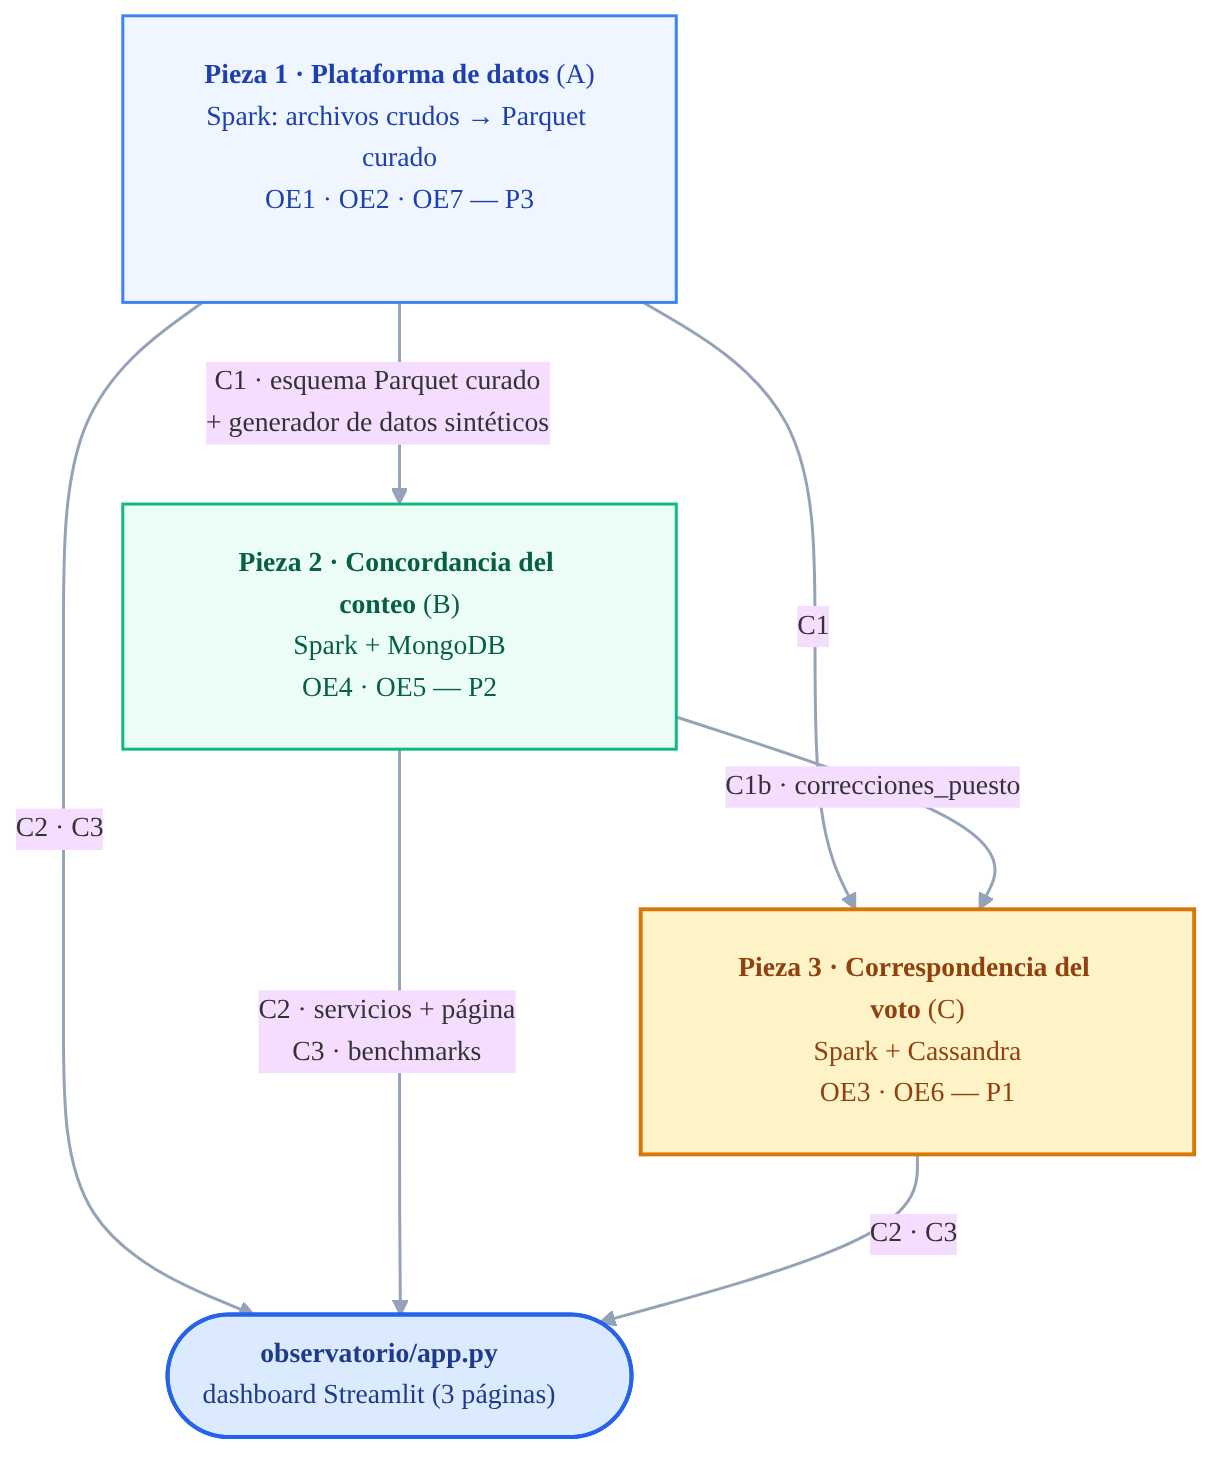

In [ ]:
mermaid(ESTILO_MERMAID + """
flowchart TB

    P1["<b>Pieza 1 · Plataforma de datos</b> (A)<br/>Spark: archivos crudos → Parquet curado<br/>OE1 · OE2 · OE7 — P3"]

    P2["<b>Pieza 2 · Concordancia del conteo</b> (B)<br/>Spark + MongoDB<br/>OE4 · OE5 — P2"]

    P3["<b>Pieza 3 · Correspondencia del voto</b> (C)<br/>Spark + Cassandra<br/>OE3 · OE6 — P1"]

    APP(["<b>observatorio/app.py</b><br/>dashboard Streamlit (3 páginas)"])

    P1 -- "C1 · esquema Parquet curado<br/>+ generador de datos sintéticos" --> P2
    P1 -- "C1" --> P3
    P2 -- "C1b · correcciones_puesto" --> P3

    P1 -- "C2 · C3" --> APP
    P2 -- "C2 · servicios + página<br/>C3 · benchmarks" --> APP
    P3 -- "C2 · C3" --> APP

    classDef data fill:#EFF6FF,stroke:#3B82F6,stroke-width:1.5px,color:#1E40AF
    classDef validation fill:#ECFDF5,stroke:#10B981,stroke-width:1.5px,color:#065F46
    classDef finding fill:#FEF3C7,stroke:#D97706,stroke-width:2px,color:#92400E
    classDef output fill:#DBEAFE,stroke:#2563EB,stroke-width:2px,color:#1E3A8A

    class P1 data
    class P2 validation
    class P3 finding
    class APP output

    linkStyle default stroke:#94A3B8,stroke-width:1.5px
""")

| | **Pieza 1 — Plataforma de datos** | **Pieza 2 — Concordancia del conteo** | **Pieza 3 — Correspondencia del voto** |
|---|---|---|---|
| **Responsable principal** | Persona A | Persona B | Persona C |
| **Objetivos** | OE1, OE2, OE7 (P3, H3) | OE4 (P2, H2), OE5 | OE3 (P1, H1), OE6 |
| **Tecnología** | Spark, Parquet, DuckDB (línea base) | Spark + MongoDB | Spark + Cassandra |
| **Entrada** | Archivos crudos de la Registraduría (ancho fijo y CSV), DIVIPOL, partidos, candidatos | Datos curados (conector 1) | Datos curados (conector 1) + correcciones por puesto (conector 1b) |
| **Salida** | Parquet curado por mesa y por puesto; tabla de puestos comparables | Correcciones por puesto y corporación (conector 1b); colección `puestos` en MongoDB | Matriz de afinidad y desvíos por puesto; tablas de consulta en Cassandra |
| **Pregunta que responde** | ¿Están los datos completos, limpios y son comparables? ¿Desde qué volumen conviene el procesamiento distribuido? (P3) | ¿Dónde y bajo qué condiciones difieren el preconteo y el escrutinio, y se cumple H2? ¿Qué pasó en este puesto? | ¿Qué listas y candidatos comparten base territorial y dónde se aparta el voto presidencial (H1)? |
| **Módulo de servicios (conector 2)** | `services/datos.py` (cobertura, puestos comparables) | `services/puestos.py` (detalle de puesto, búsqueda de candidatos) | `services/territorios.py` (resultados, afinidad, desvíos) |
| **Página del dashboard** | Calidad y cobertura de los datos; rendimiento | Buscador y detalle de puesto con sus correcciones | Tablas de afinidad y de desvíos por territorio |
| **Mediciones (conector 3)** | Escalabilidad del ETL; consultas Q1–Q3 en Spark y DuckDB | Consultas Q1–Q3 en MongoDB | Consultas Q1–Q3 en Cassandra con carga concurrente |

#### Conectores entre piezas

Un **conector** es un acuerdo escrito sobre cómo pasa la información de una pieza a otra: qué datos se entregan, con qué nombres y en qué formato. Funciona como los encajes de un lego: si cada pieza respeta la forma de sus conectores, las piezas se unen sin tener que modificarlas. Los conectores se documentan en la carpeta `conectores/` del repositorio.

**Conector 1 — Datos curados** (de la Pieza 1 a las piezas 2 y 3)

Define los archivos Parquet que entrega la Pieza 1. Incluye un **generador de datos de prueba** con la misma estructura que los datos reales, para que los análisis de las piezas 2 y 3 se puedan desarrollar y probar desde el final de la semana 1, mientras se termina el procesamiento de los datos reales.

| Dataset | Granularidad | Columnas principales |
|---|---|---|
| `resultados_mesa` | mesa × opción × conteo | `eleccion, corporacion, conteo (PRECONTEO/ESCRUTINIO), puesto_id, mesa, opcion_id, tipo_opcion (LISTA/CANDIDATO/BLANCO/NULO/NO_MARCADO), partido_id, candidato_id, votos` |
| `resultados_puesto` | puesto × opción × conteo | Igual que la anterior, agregada por puesto, más `potencial, votantes, n_mesas` |
| `puestos` | puesto | `puesto_id, cod_registraduria, divipola_dane, departamento, municipio, zona, nombre_puesto` |
| `puestos_comparables` | puesto | `puesto_id, mismo_nombre, cambio_potencial, comparable_2pct, comparable_5pct, comparable_10pct` |
| `opciones` | opción | `opcion_id, eleccion, corporacion, partido_id, candidato_id, nombre, retirado` |

**Conector 1b — Correcciones** (de la Pieza 2 a la Pieza 3)

Dataset `correcciones_puesto` (`puesto_id, corporacion, correccion_absoluta, correccion_relativa, hubo_correccion`). La Pieza 3 lo usa como control de calidad para P1: comprueba que los desvíos no se deban a errores de conteo. Hasta el final de la semana 3 se usa su versión de prueba.

**Conector 2 — Integración en el dashboard**

- Cada pieza aporta un módulo de servicios en `observatorio/services/`, con funciones de consulta documentadas (parámetros y forma de la respuesta) que leen directamente de su motor.
- Cada pieza aporta una página de Streamlit en `observatorio/pages/` que usa esos servicios.
- `observatorio/app.py` reúne las tres páginas en un solo dashboard.

**Conector 3 — Medición del rendimiento**

- Cada pieza registra sus tiempos en `benchmarks/<pieza>.csv` con las columnas `pieza, motor, consulta_id, n_registros, nucleos, concurrencia, latencia_ms, timestamp`.
- Las tres consultas de referencia, que se resuelven en cada motor, son:
  - **Q1:** votos de un candidato o lista por municipio.
  - **Q2:** detalle de un puesto en las dos elecciones.
  - **Q3:** los 100 puestos con mayor desvío o corrección en un departamento.
- Un notebook común reúne los tres archivos y genera la comparación de P3.

#### Cómo encajan las piezas

1. **Cada pieza se puede probar por sí misma** con los datos de prueba, lo que permite detectar errores antes de unirla con las demás.
2. **Unir las piezas es cambiar la fuente de datos:** la variable `DATA_PATH` pasa de los datos de prueba a los datos reales, sin modificar el código.
3. **Los conectores se definen en la semana 1.** Después solo se amplían (columnas o funciones nuevas); cualquier otro cambio se acuerda entre todo el equipo.
4. **Seguimiento:** el avance se registra en el tablero del proyecto y los cambios entran al repositorio por *pull request* revisado por otro integrante. Además, hay **tres revisiones de integración**: al final de la semana 1 (conectores definidos), de la semana 3 (integración con datos reales) y de la semana 4 (entrega final, miércoles 16 de diciembre).

#### Cronograma

| Semana | Pieza 1 — Plataforma de datos (A) | Pieza 2 — Concordancia del conteo (B) | Pieza 3 — Correspondencia del voto (C) | Hito |
|---|---|---|---|---|
| 1 (19–25 nov) | Descarga de archivos; documentar el formato de ancho fijo; perfilado; definir el conector 1 y el generador de datos de prueba | Definir el conector 2; diseñar el documento de puesto; instalar MongoDB | Definir el conector 3; diseñar las tablas por consulta; instalar Cassandra | **Revisión 1: conectores definidos.** Entregable 1 |
| 2 (26 nov – 2 dic) | ETL de Senado, Cámara y Presidencia; cruce Registraduría–DANE; puestos comparables con los umbrales de 2 %, 5 % y 10 % (parámetro); **datos reales disponibles** | Métrica de corrección y tratamiento de los retirados, con datos de prueba; carga de prueba en MongoDB | Métricas de afinidad y de desvío, con datos de prueba; carga de prueba en Cassandra | Datos reales disponibles |
| 3 (3–9 dic) | Línea base en DuckDB; escalabilidad de Spark (1, 2, 4 y 8 núcleos); Q1–Q3 en Spark y DuckDB | Correcciones con datos reales; prueba de H2; **entrega de `correcciones_puesto` (conector 1b)**; carga real en MongoDB y búsqueda por texto | Matriz de afinidad y desvíos con datos reales; carga real en Cassandra (mesas del Senado y tablas por territorio) | **Revisión 2: integración con datos reales** |
| 4 (10–16 dic) | Página de datos y rendimiento; informe de P3 (H3) | Q1–Q3 en MongoDB; página del dashboard; informe de P2 (H2) | Prueba de H1 con el control de P2; pruebas de carga (p99); página del dashboard; informe de P1 (H1) | **Revisión 3: entrega final (16 dic)** |

**Diagrama de Gantt**

In [4]:
# ============================================================
# DIAGRAMA DE GANTT (4 semanas, entrega final el miércoles 16 de diciembre)
# Las semanas van de jueves a miércoles para que la semana 4 termine
# justo el día de la entrega. INICIO se calcula a partir de FIN.
# Cada actividad: (sección, nombre, semana de inicio, duración en semanas)
# No use ":" en los nombres: Mermaid lo usa como separador.
# ============================================================
from datetime import date, timedelta

FIN = date(2026, 12, 16)
SEMANAS = 4
INICIO = FIN - timedelta(weeks=SEMANAS) + timedelta(days=1)

def semana(n):
    return INICIO + timedelta(weeks=n - 1)

def fin_de_semana(n):
    return semana(n) + timedelta(days=6)

ACTIVIDADES = [
    ("Todos",                "Definición de los conectores y entregable 1", 1, 1),
    ("Todos",                "Integración, informes y presentación",        4, 1),
    ("Pieza 1 · Datos (A)",  "Descarga, formato y perfilado",               1, 1),
    ("Pieza 1 · Datos (A)",  "ETL, cruce DANE, comparables y umbrales",     2, 1),
    ("Pieza 1 · Datos (A)",  "Línea base DuckDB y escalabilidad de Spark",  3, 1),
    ("Pieza 1 · Datos (A)",  "Página de datos e informe de P3",             4, 1),
    ("Pieza 2 · Conteo (B)", "Diseño e instalación de MongoDB",             1, 1),
    ("Pieza 2 · Conteo (B)", "Métrica de corrección (datos de prueba)",     2, 1),
    ("Pieza 2 · Conteo (B)", "Correcciones reales y prueba de H2",          3, 1),
    ("Pieza 2 · Conteo (B)", "Mediciones, dashboard e informe de P2",       4, 1),
    ("Pieza 3 · Voto (C)",   "Diseño e instalación de Cassandra",           1, 1),
    ("Pieza 3 · Voto (C)",   "Afinidad y desvío (datos de prueba)",         2, 1),
    ("Pieza 3 · Voto (C)",   "Afinidad real y carga en Cassandra",          3, 1),
    ("Pieza 3 · Voto (C)",   "Prueba de H1, latencia e informe de P1",      4, 1),
]

HITOS = [
    ("Revisión 1 · conectores definidos",   1),
    ("Datos reales disponibles",            2),
    ("Revisión 2 · datos reales",           3),
    ("Revisión 3 · entrega final",          4),
]

lineas = [
    "gantt",
    f"    title Plan del proyecto ({SEMANAS} semanas, entrega {FIN:%d/%m/%Y})",
    "    dateFormat YYYY-MM-DD",
    "    axisFormat %d %b",
    "    todayMarker off",
]
seccion_actual = None
for i, (seccion, nombre, inicio, semanas) in enumerate(ACTIVIDADES):
    if seccion != seccion_actual:
        lineas.append(f"    section {seccion}")
        seccion_actual = seccion
    lineas.append(f"    {nombre.replace(':', ' ·')} :t{i}, {semana(inicio)}, {7 * semanas}d")
lineas.append("    section Hitos")
for j, (nombre, sem) in enumerate(HITOS):
    lineas.append(f"    {nombre} :milestone, m{j}, {fin_de_semana(sem)}, 0d")

GANTT = "\n".join(lineas)
mermaid(GANTT)

#### Riesgos y mitigación

| Riesgo | Impacto | Mitigación |
|---|---|---|
| El formato de ancho fijo está mal documentado o cambia entre archivos | Alto | Perfilado en la semana 1; validar los totales por departamento contra los boletines oficiales |
| Las llaves no coinciden entre fuentes (zona, partido, corporación, códigos DANE) | Alto | Tablas de correspondencia versionadas en el repositorio; reporte de registros sin pareja |
| El procesamiento de los datos reales se retrasa y demora los análisis | Alto | Datos de prueba con la estructura final desde la semana 1; fecha firme para los datos reales al final de la semana 2 (2 de diciembre) |
| El tiempo no alcanza para todos los requisitos | Alto | Se garantizan primero los requisitos de prioridad **M**; los de prioridad **S** quedan como mejora si queda tiempo |
| El volumen supera la memoria de los equipos personales | Medio | Desarrollo con muestras; procesamiento por particiones; corridas completas solo al final |
| La carga de las mesas del Senado en Cassandra tarda horas en un portátil | Medio | Carga por lotes y por departamento, probada primero con una muestra; si no alcanza el tiempo, se limita a un subconjunto de departamentos |
| Alguna hipótesis no se cumple | Bajo | Es un resultado válido: se reporta con la misma rigurosidad |
| Se malinterpretan los resultados como evidencia de fraude o de voto individual | Medio | Notas metodológicas en el dashboard sobre la falacia ecológica y el alcance descriptivo |

## **2. Definición del diseño y/o arquitectura de la solución**
---


### **2.1. Descripción**
---

- ¿Cómo se estructura la solución propuesta?
- ¿Cuáles son los componentes clave de la solución?
- ¿Existen opciones de diseño alternativas y cuáles son sus ventajas y desventajas?

#### ¿Cómo se estructura la solución propuesta?

##### Marco de referencia

La arquitectura se describe siguiendo tres referentes:

| Referente | Uso en este documento |
|---|---|
| **ISO/IEC/IEEE 42010:2022** — *Architecture description* | Organiza la descripción en **vistas**, cada una dirigida a las preocupaciones de un grupo interesado, y exige justificar las **decisiones de arquitectura**. |
| **ISO/IEC 20547-3:2020** — *Big data reference architecture* | Aporta los **roles** del ecosistema de big data (vista de usuario) y las **actividades** de la aplicación (vista funcional): recolección, preparación, analítica, visualización y acceso. |
| **Modelo C4** (Brown) | Notación de los diagramas: nivel 1 (contexto) y nivel 2 (contenedores; en C4, «contenedor» designa una aplicación o un almacén de datos, no un contenedor Docker). No es una norma, pero se usa ampliamente para comunicar arquitecturas. |

##### Impulsores de la arquitectura

La estructura responde a cuatro impulsores, que salen de las preguntas del proyecto y de las características de los datos:

| # | Impulsor | Origen | Consecuencia en el diseño |
|---|---|---|---|
| IA1 | Datos heterogéneos (ancho fijo y CSV), con llaves que no coinciden entre fuentes y sistemas de códigos distintos | Registraduría y DANE | Una capa de integración explícita, con tablas de correspondencia versionadas |
| IA2 | Volumen de ~10 GB y ~180 millones de registros a nivel de mesa | OE1, P3 | Procesamiento distribuido y almacenamiento columnar particionado |
| IA3 | Los datos se escriben una vez y se leen muchas: los resultados de 2026 ya no cambian | Naturaleza del dominio | El cálculo costoso se hace por lotes y cada consulta lee un resultado ya calculado |
| IA4 | Consultas de baja latencia y comparación rigurosa entre tecnologías | OE5–OE7, P3 | Una capa de consulta con dos motores especializados, y medición del rendimiento incorporada desde el diseño |

##### Estructura general

La solución es un **sistema analítico de solo lectura**. Tiene dos partes:

1. Un **procesamiento por lotes organizado en capas *medallion***:
   - ***bronze*:** archivos originales sin modificar;
   - ***silver*:** datos limpios e integrados a nivel de mesa;
   - ***gold*:** datos agregados a nivel de puesto y resultados de los análisis.
2. Una **capa de consulta políglota** (*polyglot persistence*): dos bases NoSQL, cada una dedicada al tipo de consulta que mejor resuelve.

##### Vista de usuario: roles según ISO/IEC 20547-3

| Rol | Quién o qué lo cumple en el proyecto |
|---|---|
| **Proveedor de datos** (*Data provider*) | Registraduría Nacional del Estado Civil (resultados mesa a mesa, DIVIPOL, partidos, candidatos) y DANE (códigos DIVIPOLA) |
| **Proveedor de la aplicación de big data** (*Big data application provider*) | El pipeline del proyecto: recolección (ingesta), preparación (ETL), analítica (P1, P2, P3), visualización y acceso (dashboard en Streamlit) |
| **Proveedor del framework de big data** (*Big data framework provider*) | Spark (procesamiento), Parquet en disco local (almacenamiento), MongoDB y Cassandra (consulta) |
| **Consumidor de datos** (*Data consumer*) | Observadores electorales, academia, periodistas y ciudadanía, a través del dashboard y de los datasets abiertos |
| **Orquestación y gestión** (transversal) | El equipo del proyecto: contratos de datos, control de versiones y orquestación de los trabajos |

##### Vista de contexto (C4, nivel 1)


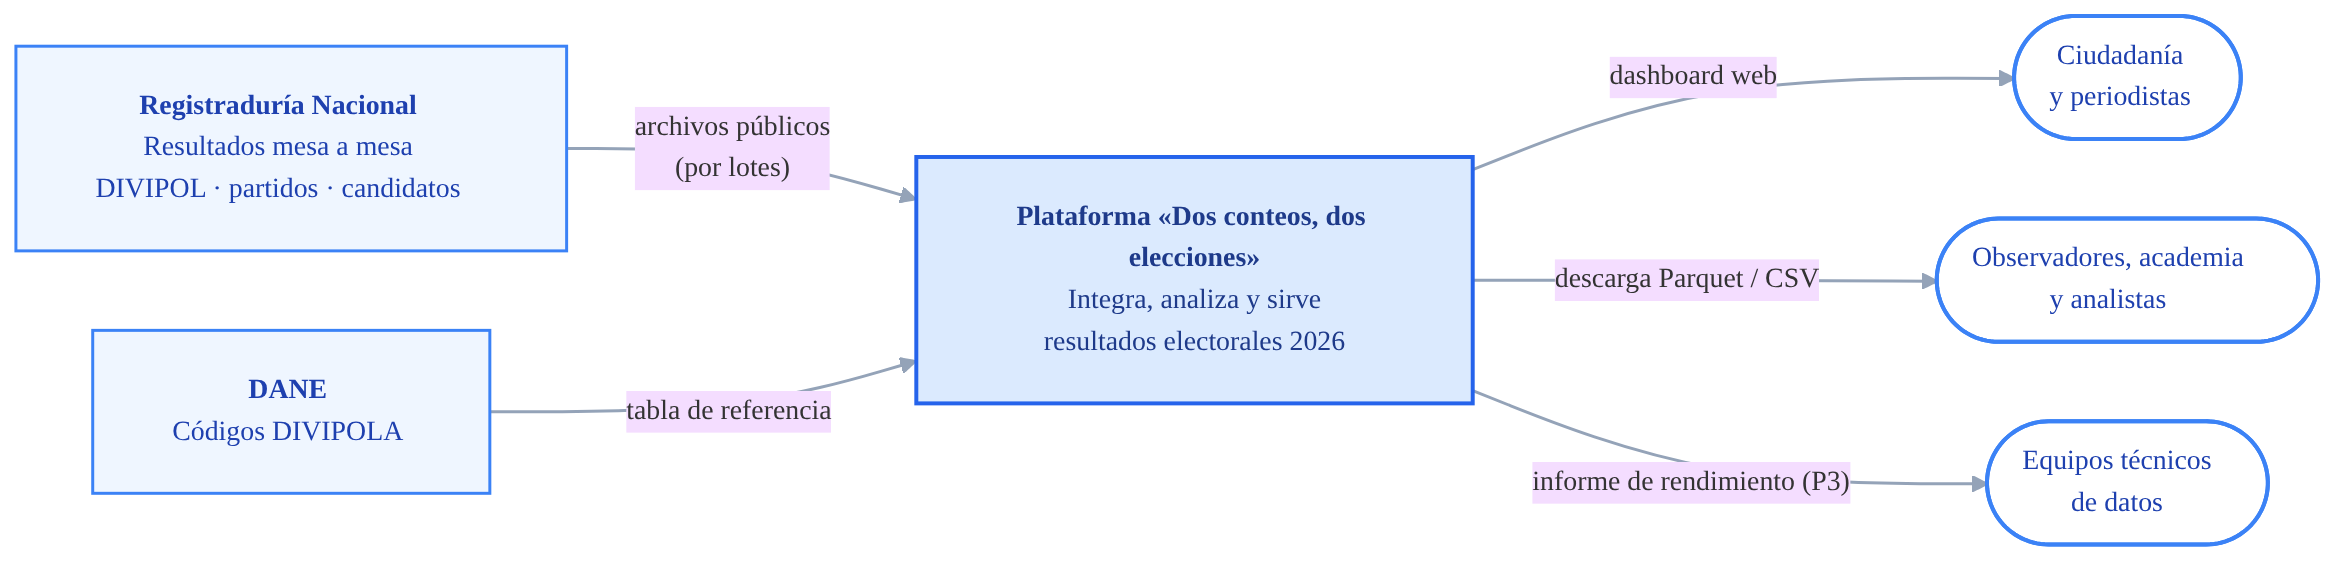

In [ ]:
mermaid(ESTILO_MERMAID + """
flowchart LR

    RNEC["<b>Registraduría Nacional</b><br/>Resultados mesa a mesa<br/>DIVIPOL · partidos · candidatos"]

    DANE["<b>DANE</b><br/>Códigos DIVIPOLA"]

    SYS["<b>Plataforma «Dos conteos, dos elecciones»</b><br/>Integra, analiza y sirve<br/>resultados electorales 2026"]

    U1(["Ciudadanía<br/>y periodistas"])
    U2(["Observadores, academia<br/>y analistas"])
    U3(["Equipos técnicos<br/>de datos"])

    RNEC -- "archivos públicos<br/>(por lotes)" --> SYS
    DANE -- "tabla de referencia" --> SYS
    SYS -- "dashboard web" --> U1
    SYS -- "descarga Parquet / CSV" --> U2
    SYS -- "informe de rendimiento (P3)" --> U3

    classDef data fill:#EFF6FF,stroke:#3B82F6,stroke-width:1.5px,color:#1E40AF
    classDef output fill:#DBEAFE,stroke:#2563EB,stroke-width:2px,color:#1E3A8A
    classDef actor fill:#FFFFFF,stroke:#3B82F6,stroke-width:2px,color:#1E40AF

    class RNEC,DANE data
    class SYS output
    class U1,U2,U3 actor

    linkStyle default stroke:#94A3B8,stroke-width:1.5px
""")


##### Vista funcional y de contenedores (C4, nivel 2)


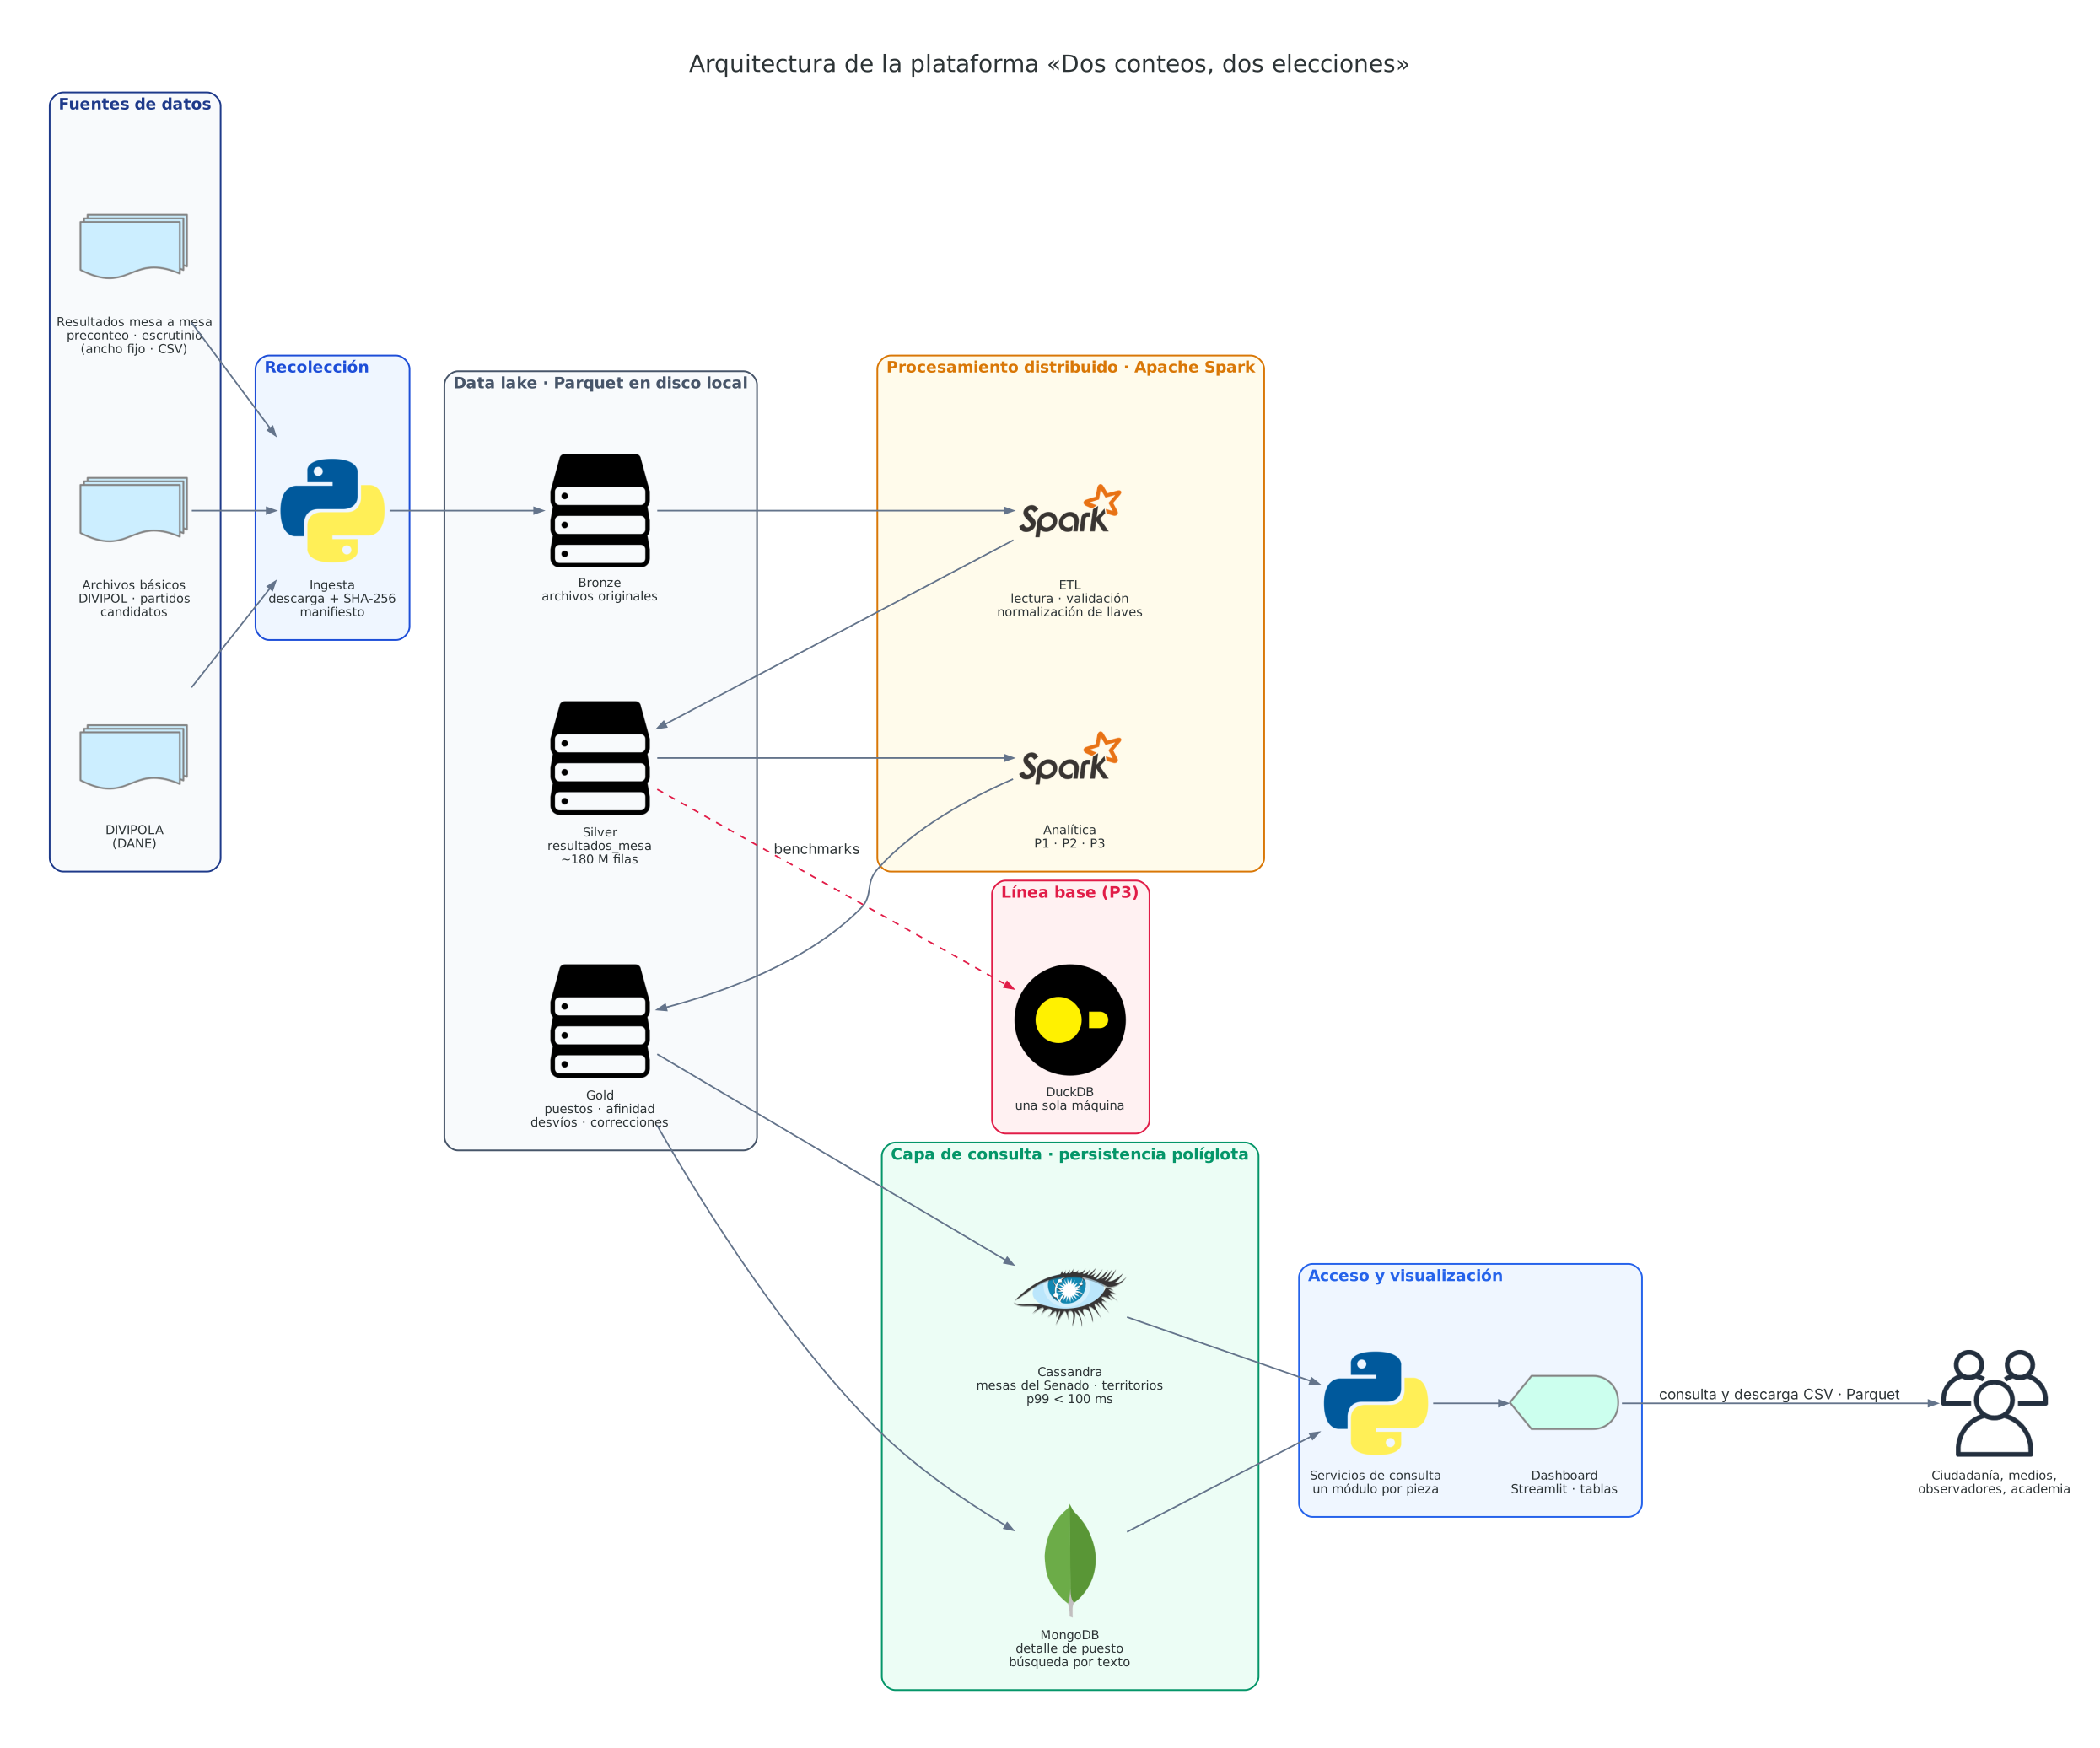

In [ ]:
# ============================================================
# VISTA FUNCIONAL Y DE CONTENEDORES (C4, nivel 2)
# ============================================================
from diagrams import Diagram, Cluster, Edge
from diagrams.onprem.client import Users
from diagrams.onprem.analytics import Spark
from diagrams.onprem.database import MongoDB, Cassandra, Duckdb
from diagrams.programming.language import Python
from diagrams.programming.flowchart import MultipleDocuments, Display
from diagrams.generic.storage import Storage
from IPython.display import Image, display

graph_attr = {
    "fontname": "Helvetica", "fontsize": "21", "bgcolor": "white",
    "pad": "0.6", "nodesep": "0.55", "ranksep": "0.9",
    "splines": "spline", "labelloc": "t",
}
node_attr = {"fontname": "Helvetica", "fontsize": "11"}
edge_attr = {"color": "#64748B", "penwidth": "1.4", "arrowsize": "0.8"}

def zona(fondo, borde):
    return {
        "bgcolor": fondo, "pencolor": borde, "penwidth": "1.5",
        "fontname": "Helvetica-Bold", "fontsize": "14", "fontcolor": borde,
        "style": "rounded", "margin": "18",
    }

with Diagram(
    "Arquitectura de la plataforma «Dos conteos, dos elecciones»",
    filename="arquitectura", outformat="png", show=False, direction="LR",
    graph_attr=graph_attr, node_attr=node_attr, edge_attr=edge_attr,
):
    with Cluster("Fuentes de datos", graph_attr=zona("#F8FAFC", "#1E3A8A")):
        mmv = MultipleDocuments("Resultados mesa a mesa\npreconteo · escrutinio\n(ancho fijo · CSV)")
        basicos = MultipleDocuments("Archivos básicos\nDIVIPOL · partidos\ncandidatos")
        dane = MultipleDocuments("DIVIPOLA\n(DANE)")

    with Cluster("Recolección", graph_attr=zona("#EFF6FF", "#1D4ED8")):
        ingesta = Python("Ingesta\ndescarga + SHA-256\nmanifiesto")

    with Cluster("Data lake · Parquet en disco local", graph_attr=zona("#F8FAFC", "#475569")):
        bronze = Storage("Bronze\narchivos originales")
        silver = Storage("Silver\nresultados_mesa\n~180 M filas")
        gold = Storage("Gold\npuestos · afinidad\ndesvíos · correcciones")

    with Cluster("Procesamiento distribuido · Apache Spark", graph_attr=zona("#FFFBEB", "#D97706")):
        etl = Spark("ETL\nlectura · validación\nnormalización de llaves")
        analitica = Spark("Analítica\nP1 · P2 · P3")

    with Cluster("Línea base (P3)", graph_attr=zona("#FFF1F2", "#E11D48")):
        duck = Duckdb("DuckDB\nuna sola máquina")

    with Cluster("Capa de consulta · persistencia políglota", graph_attr=zona("#ECFDF5", "#059669")):
        mongo = MongoDB("MongoDB\ndetalle de puesto\nbúsqueda por texto")
        cass = Cassandra("Cassandra\nmesas del Senado · territorios\np99 < 100 ms")

    with Cluster("Acceso y visualización", graph_attr=zona("#EFF6FF", "#2563EB")):
        servicios = Python("Servicios de consulta\nun módulo por pieza")
        dash = Display("Dashboard\nStreamlit · tablas")

    usuarios = Users("Ciudadanía, medios,\nobservadores, academia")

    [mmv, basicos, dane] >> ingesta >> bronze >> etl >> silver >> analitica >> gold
    silver >> Edge(style="dashed", color="#E11D48", label="benchmarks") >> duck
    gold >> mongo
    gold >> cass
    mongo >> servicios
    cass >> servicios
    servicios >> dash
    dash >> Edge(label="consulta y descarga CSV · Parquet") >> usuarios

display(Image("arquitectura.png"))

##### Flujo de los datos

1. La **ingesta** descarga los archivos y los guarda sin cambios en *bronze*.
2. **Spark** los lee, valida e integra en *silver*.
3. **Spark** los agrega y ejecuta los análisis de P1 y P2, cuyos resultados quedan en *gold*.
4. Desde *gold* se cargan las vistas precalculadas en **MongoDB** y **Cassandra**.
5. Los **servicios de consulta** de cada pieza leen de MongoDB o de Cassandra, según el tipo de consulta, y el **dashboard** muestra los resultados.

Cada etapa mide sus tiempos para responder P3.

#### ¿Cuáles son los componentes clave de la solución?


Los componentes se organizan según las actividades del proveedor de la aplicación de big data de ISO/IEC 20547-3 (recolección, preparación, analítica, acceso y visualización), más el almacenamiento que los soporta.

| # | Componente | Actividad (ISO/IEC 20547-3) | Tecnología | Objetivos |
|---|---|---|---|---|
| C1 | Ingesta | Recolección | Python | OE1 |
| C2 | ETL distribuido | Preparación | Apache Spark (PySpark) | OE1, OE2 |
| C3 | Analítica | Analítica | Apache Spark + estadística | OE3, OE4, OE7 |
| C4 | Almacenamiento curado | Soporte (*framework*) | Parquet en disco local | OE1 |
| C5 | NoSQL documental | Acceso | MongoDB | OE5 |
| C6 | NoSQL columnar | Acceso | Apache Cassandra | OE6 |
| C7 | Servicios de consulta | Acceso | Python (un módulo por pieza) | OE5, OE6 |
| C8 | Dashboard | Visualización | Streamlit | P1, P2 |

##### C1. Ingesta

- Scripts en Python que descargan los archivos públicos de la Registraduría y los guardan **sin modificar** en la capa *bronze*.
- Un manifiesto (`manifest.json`) registra la URL de origen, la fecha de descarga, el tamaño y el *hash* SHA-256 de cada archivo. Así cualquier resultado se puede rastrear hasta su archivo de origen y la descarga se puede repetir.

##### C2. ETL distribuido — Apache Spark

Transforma la capa *bronze* en la capa *silver* en cuatro pasos:

1. **Lectura:** los archivos de ancho fijo se leen como texto y los campos se extraen por posición, según una especificación de diseño de registro versionada en el repositorio (`layouts/*.yaml`). Los CSV se leen con su codificación original y se convierten a UTF-8.
2. **Validación:** se comprueban el esquema, los tipos y los rangos, y se cuadran los totales de control por departamento contra los boletines oficiales. Los registros inválidos van a una tabla de **cuarentena** con su motivo, en vez de descartarse en silencio.
3. **Normalización de llaves:** zona, partido y corporación se unifican entre fuentes, y los códigos de la Registraduría se cruzan con los códigos DIVIPOLA del DANE mediante tablas de correspondencia versionadas. Los registros sin pareja se reportan.
4. **Unificación:** preconteo y escrutinio de Senado, Cámara y Presidencia quedan en un solo esquema largo (`resultados_mesa`), con una marca para los candidatos retirados.

##### C3. Analítica — Apache Spark + estadística

Transforma *silver* en *gold* y responde las preguntas del proyecto:

| Producto *gold* | Pregunta | Método |
|---|---|---|
| `resultados_puesto` | Todas | Agregación de mesa a puesto, municipio y departamento |
| `puestos_comparables` | P1 | Mismo nombre y cambio de potencial < 5 %, con corridas adicionales al 2 % y al 10 % |
| `afinidad_lista_candidato` | P1 | Correlación entre puestos, ponderada por votantes, entre la participación de cada lista al Senado (lista + preferentes) y la de cada candidato presidencial, a nivel nacional y dentro de cada departamento |
| `desvios_puesto` | P1 | Residuo estandarizado de una regresión lineal simple del voto presidencial sobre la participación de las principales listas al Senado en el mismo puesto |
| `correcciones_puesto` | P2 | Corrección relativa = Σ\|escrutinio − preconteo\| / votos válidos, por puesto y corporación, sin contar el traslado de votos de retirados. Prueba de tendencia pareada dentro del mismo puesto (Page), con intervalos por *bootstrap* |
| `benchmarks` | P3 | Tiempos de los trabajos y de las consultas, en el formato común del contrato C3 |

**Decisiones de diseño distribuido.** El costo de cada operación se modela como *T(n, p) ≈ W/p + D + C/B + R·L*, donde:

- *W* es el trabajo total;
- *D* es la profundidad, o camino crítico;
- *C* es el volumen comunicado en el *shuffle*;
- *B* es el ancho de banda;
- *R* es el número de rondas de sincronización (*stages*);
- *L* es la latencia de cada ronda.

Las decisiones buscan reducir el término que más pesa en cada operación:

| Operación | Decisión | Término que reduce |
|---|---|---|
| Cruce con DIVIPOL, partidos y candidatos | *Broadcast hash join*: las tablas pequeñas se copian a cada nodo | *C*: la tabla grande no viaja por la red |
| Agregación de mesa a puesto | `groupBy`/`agg` con combinación local antes del *shuffle* | *C*: se transmite proporcional al número de puestos, no de registros |
| Unión de preconteo y escrutinio | Ambos conjuntos particionados por `puesto_id` (*bucketing*) | *C* y *R*: el join se hace sin *shuffle* adicional |
| Claves muy grandes (Bogotá, Antioquia) | *Salting* y *Adaptive Query Execution* | *D*: ninguna partición domina el tiempo total |
| Matriz de afinidad lista × candidato | Se calcula sobre la tabla de puestos ya agregada | *W*: el cálculo cuadrático se hace sobre decenas de miles de filas, no sobre millones |
| Lectura de Parquet | Poda de particiones y de columnas | E/S: solo se lee lo necesario |

##### C4. Almacenamiento curado — Parquet en disco local

- **Parquet:** formato columnar con compresión y *predicate pushdown*, particionado por `eleccion/corporacion/departamento`.
- **Disco local:** los archivos se guardan en la carpeta de datos del repositorio (`data/`), organizados por capa (*bronze*, *silver*, *gold*); no se requiere ningún servicio adicional.
- Es la **fuente de verdad** del sistema: MongoDB y Cassandra se pueden reconstruir desde aquí en cualquier momento.

##### C5. NoSQL documental — MongoDB

**Modelo:** un documento por puesto con toda su información (las dos elecciones, los dos conteos, la comparabilidad, las correcciones y los desvíos). La estructura anidada acomoda las diferencias entre corporaciones: listas con voto preferente, listas cerradas y candidatos presidenciales.

Se elige **embeber** en vez de referenciar por dos razones: el patrón de acceso es "todo sobre un puesto", y el documento queda muy por debajo del límite de 16 MB.

```json
{
  "_id": "05-001-01-003",
  "departamento": "ANTIOQUIA", "municipio": "MEDELLIN", "divipola_dane": "05001",
  "zona": "01", "puesto": "003", "nombre": "...",
  "comparable": { "mismo_nombre": true, "cambio_potencial": 0.012, "umbral_5pct": true },
  "elecciones": {
    "SENADO_2026": {
      "potencial": 4820, "votantes": 2310, "n_mesas": 14,
      "opciones": [
        { "partido_id": 5, "tipo": "LISTA",
          "voto_lista": { "preconteo": 120, "escrutinio": 121 },
          "candidatos": [ { "candidato_id": 3, "nombre": "...", "preconteo": 88, "escrutinio": 88 } ] }
      ]
    },
    "CAMARA_2026": { "...": "..." },
    "PRESIDENCIA_2026_V1": { "...": "..." }
  },
  "correcciones": { "SENADO": 0.004, "CAMARA": 0.002, "PRESIDENCIA": 0.000 },
  "desvios": [ { "candidato_id": 2, "residuo": 1.8 } ]
}
```

**Índices:**

- compuesto `(departamento, municipio)`;
- de texto sobre los nombres de candidatos, con *collation* insensible a tildes;
- *multikey* sobre los `candidato_id`.

##### C6. NoSQL columnar — Apache Cassandra

**Modelo orientado a consultas:** hay una tabla por cada consulta frecuente, de modo que cada consulta lee **una sola partición**. Las dos tablas a nivel de mesa se cargan solo con el Senado, la corporación con más registros, para que el volumen justifique el motor sin que la carga se vuelva inmanejable en un portátil.

| Consulta | Tabla | *Partition key* | *Clustering key* |
|---|---|---|---|
| Resultados de un puesto, mesa por mesa (Senado) | `resultados_mesa_puesto` | `(eleccion, corporacion, puesto_id)` | `mesa, opcion_id, conteo` |
| Votos de una opción en las mesas de un municipio (Senado) | `votos_opcion_mesa` | `(eleccion, corporacion, opcion_id, divipola)` | `puesto_id, mesa` |
| Votos de una opción por municipio | `votos_opcion_municipio` | `(eleccion, corporacion, opcion_id)` | `divipola` |
| Puestos con mayor corrección | `correcciones_depto` | `(corporacion, departamento)` | `correccion_relativa DESC, puesto_id` |
| Candidatos más afines a una lista | `afinidad_lista` | `(ambito, lista_id)` | `afinidad DESC, candidato_id` |
| Puestos con mayor desvío de un candidato | `desvios_candidato_depto` | `(candidato_id, departamento)` | `residuo DESC, puesto_id` |

**Configuración:**

- Instancia local de un solo nodo, con factor de replicación 1. El modelo de datos no cambia si más adelante se agregan nodos.
- Consistencia `ONE` en las lecturas de las pruebas de carga.
- Particiones de ~100 MB como máximo. Por eso la tabla de mesas incluye `divipola` en la clave: así ninguna partición abarca todo el país.

##### C7. Servicios de consulta — Python

- Un módulo por pieza del proyecto en `observatorio/services/` (contrato C2): `datos.py`, `puestos.py` y `territorios.py`.
- Cada función se dirige al motor adecuado: las consultas fijas a Cassandra; el detalle de un puesto y la búsqueda de texto a MongoDB.
- Cada consulta mide su latencia con `time.perf_counter_ns` y la registra en el formato del contrato C3.
- No se expone una API REST para terceros; queda como extensión futura (ver ADR-08).

##### C8. Dashboard — Streamlit

Tiene una página por pieza del proyecto, en `observatorio/pages/`:

1. **Datos:** calidad y cobertura (puestos cargados, excluidos y comparables) y rendimiento (P3).
2. **Puestos:** buscador de candidatos y detalle de un puesto en las dos elecciones y los dos conteos (P2).
3. **Territorio:** tablas y gráficos por departamento y municipio de afinidad, desvíos y correcciones (P1 y P2).

Cada página permite descargar en CSV los resultados que muestra. Cada página muestra notas metodológicas sobre la falacia ecológica y el alcance descriptivo del análisis.

#### ¿Existen opciones de diseño alternativas? Ventajas y desventajas

ISO/IEC/IEEE 42010 pide que las decisiones de arquitectura queden registradas con su justificación. Por eso cada decisión se documenta como un *Architecture Decision Record* (ADR), con el contexto, las opciones evaluadas, sus ventajas y desventajas, y la decisión tomada.

##### ADR-01. Patrón de arquitectura

**Contexto:** los resultados de 2026 son históricos y no cambian (IA3).

| Opción | Ventajas | Desventajas |
|---|---|---|
| **Por lotes con capas *medallion*** | Simple; reproducible; cada capa se puede auditar; encaja con datos inmutables | No procesa datos en tiempo real |
| Lambda (lotes + *streaming*) | Combina historia y tiempo real | Dos rutas de código que mantener; el *streaming* no aporta nada con datos estáticos |
| Kappa (solo *streaming*) | Un solo modelo de procesamiento | Reprocesar el histórico es costoso; agrega complejidad sin beneficio |

**Decisión:** por lotes. La arquitectura deja preparada una capa de *streaming* para futuras elecciones (ver 2.2, escalabilidad).

##### ADR-02. Unidad de análisis

**Contexto:** se necesita una unidad en la que el electorado sea comparable entre marzo y mayo.

| Opción | Ventajas | Desventajas |
|---|---|---|
| **Puesto de votación** | El 99,8 % conserva el nombre; corresponde al mismo lugar y al mismo electorado | Menos detalle que la mesa |
| Mesa | Máximo detalle y más observaciones | Solo el 63,4 % de los puestos conserva el mismo número de mesas, así que la mesa no garantiza los mismos votantes |
| Municipio | Siempre comparable; menos datos | Pierde la variación dentro del municipio, que es justamente lo que interesa medir |

**Decisión:** el puesto para el análisis. La mesa se conserva para las consultas de detalle y para las pruebas de volumen de P3.

##### ADR-03. Motor de procesamiento

**Contexto:** ~10 GB y ~180 millones de registros (IA2), y la pregunta P3 sobre cuándo conviene distribuir.

| Opción | Ventajas | Desventajas |
|---|---|---|
| **Apache Spark** | Escala horizontalmente; ecosistema maduro; conectores para MongoDB y Cassandra | Mayor costo de arranque y operación; con volúmenes pequeños puede ser más lento |
| DuckDB / Polars (una máquina) | Muy rápidos con pocos GB; sin clúster que operar | No escalan horizontalmente; dependen de la memoria y el disco de un equipo |
| Dask | Basado en Python; API parecida a pandas | Ecosistema de conectores menos maduro; menor adopción en la industria |

**Decisión:** Spark. **DuckDB se incluye como línea base** para responder P3 con datos.

##### ADR-04. Almacenamiento curado

**Contexto:** se necesita una fuente de verdad reproducible entre el procesamiento y la consulta.

| Opción | Ventajas | Desventajas |
|---|---|---|
| **Parquet en disco local** | Formato columnar abierto y comprimido; poda de particiones y columnas; no requiere ningún servicio adicional | Limitado al disco de cada equipo; para compartir datos entre integrantes se regeneran desde la capa *bronze* |
| Parquet sobre HDFS | Integración nativa con Hadoop; almacenamiento distribuido | Requiere NameNode y DataNodes; demasiado pesado para equipos personales |
| Sin capa curada (solo las bases NoSQL) | Menos componentes | Se pierde la reproducibilidad; las bases NoSQL no son eficientes para el análisis masivo de Spark |

**Decisión:** Parquet en disco local.

##### ADR-05. NoSQL columnar

**Contexto:** consultas fijas con latencia p99 < 100 ms bajo carga concurrente (IA4).

| Opción | Ventajas | Desventajas |
|---|---|---|
| **Apache Cassandra** | Lecturas por partición con latencia estable; escala agregando nodos; sin punto único de falla; instalación sencilla | Exige diseñar una tabla por consulta; no permite consultas *ad hoc* ni joins |
| HBase | Consistencia fuerte; integración con Hadoop | Requiere HDFS y ZooKeeper; más difícil de operar |
| ScyllaDB | Compatible con Cassandra y con menor latencia | Menos documentación y comunidad |
| ClickHouse | Agregaciones *ad hoc* muy rápidas | Es un motor OLAP, no un almacén diseñado por consulta; no sirve para demostrar el modelado orientado a consultas |

**Decisión:** Cassandra. El diseño es portable a ScyllaDB sin cambios, porque usa el mismo protocolo y CQL.

##### ADR-06. NoSQL documental

**Contexto:** detalle de puesto con estructura distinta por corporación, y búsqueda de candidatos por nombre.

| Opción | Ventajas | Desventajas |
|---|---|---|
| **MongoDB** | Esquema flexible para datos anidados y heterogéneos; índices secundarios y de texto; *aggregation pipeline* | La búsqueda de texto es más limitada que la de un motor especializado |
| Elasticsearch | Búsqueda de texto completo superior (relevancia, *fuzzy*) | Otro sistema que operar; no está pensado como almacén principal |
| PostgreSQL con JSONB | SQL, transacciones y documentos JSON en un solo motor | No cumple el requisito de NoSQL del curso |

**Decisión:** MongoDB. Su índice de texto basta para buscar nombres de candidatos.

##### ADR-07. Una o varias bases de consulta

**Contexto:** hay dos patrones de acceso distintos: "todo sobre un puesto" y "consultas fijas sobre muchos territorios".

| Opción | Ventajas | Desventajas |
|---|---|---|
| **Persistencia políglota (MongoDB + Cassandra)** | Cada motor atiende el patrón para el que es óptimo; permite compararlos en P3 | Dos sistemas que cargar y mantener; los datos se duplican |
| Solo MongoDB | Un solo motor | Las consultas agregadas sobre ~180 M de filas serían más lentas e inestables |
| Solo Cassandra | Un solo motor | No sirve bien para documentos anidados ni para búsqueda de texto |

**Decisión:** persistencia políglota. La duplicación de datos no es un problema porque los datos no cambian: ambas bases se cargan una vez desde *gold*.

##### ADR-08. Acceso a los datos desde el dashboard

**Contexto:** el dashboard necesita leer de MongoDB y de Cassandra, y el proyecto dispone de 5 semanas con unas 10 horas semanales por persona.

| Opción | Ventajas | Desventajas |
|---|---|---|
| **Servicios de consulta en Python, usados directamente por Streamlit** | Menos código y menos componentes; encaja con la estructura del repositorio (`observatorio/services/`); la latencia se mide directamente en el *driver* de cada base | No ofrece acceso programático a terceros |
| API REST (FastAPI + OpenAPI 3) | Estándar; otras aplicaciones la pueden consumir; documentación automática | Una capa más que construir, probar y medir |
| GraphQL | El cliente pide exactamente los campos que necesita | Riesgo de consultas N+1; más difícil de medir |

**Decisión:** servicios de consulta en Python. Una API REST queda como extensión futura si terceros necesitan acceso programático.


##### Resumen de decisiones

| ADR | Decisión | Alternativa principal descartada | Razón principal |
|---|---|---|---|
| 01 | Por lotes, capas *medallion* | Lambda / Kappa | Datos inmutables |
| 02 | Puesto | Mesa | Electorado comparable |
| 03 | Spark (+ DuckDB como línea base) | Una sola máquina | Escalabilidad y P3 |
| 04 | Parquet en disco local | HDFS | Simple y sin servicios adicionales |
| 05 | Cassandra | HBase | Operación simple y latencia estable |
| 06 | MongoDB | Elasticsearch | Esquema flexible con búsqueda suficiente |
| 07 | Persistencia políglota | Un solo motor | Dos patrones de acceso distintos |
| 08 | Servicios en Python + Streamlit | API REST (FastAPI) | Menos componentes para 5 semanas |

### **2.2. Restricciones y escalabilidad**
---

- ¿Cuáles son los requisitos funcionales y no funcionales de la solución?
- ¿Existen restricciones tecnológicas, presupuestarias o de tiempo que deben tenerse en cuenta en el diseño?
- ¿Cómo se abordará la escalabilidad de la solución a medida que crezcan los datos o las necesidades del negocio?
- ¿Cómo se integrará la nueva solución con los sistemas existentes en la organización?

#### ¿Cuáles son los requisitos funcionales y no funcionales de la solución?

##### Marco normativo

| Norma | Uso |
|---|---|
| **ISO/IEC/IEEE 29148:2018** — *Requirements engineering* | Forma de redactar y gestionar los requisitos. Cada requisito es **singular, no ambiguo, factible y verificable**, usa la construcción *"El sistema deberá…"* (equivalente al *shall* de la norma) y tiene identificador, prioridad, trazabilidad a su origen y método de verificación. |
| **ISO/IEC 25010:2023** — Modelo de calidad del producto (SQuaRE) | Clasificación de los requisitos no funcionales según sus nueve características de calidad: adecuación funcional, eficiencia de desempeño, compatibilidad, capacidad de interacción, fiabilidad, seguridad, mantenibilidad, flexibilidad y protección (*safety*). |
| **ISO/IEC 25012:2008** — Modelo de calidad de datos (SQuaRE) | Requisitos de calidad de los datos curados: exactitud, completitud, consistencia y trazabilidad, entre otros. |
| **ISO/IEC 20547-3:2020** — Arquitectura de referencia de big data | Agrupación de los requisitos funcionales por actividad: recolección, preparación, analítica, acceso y visualización. |

**Convenciones**

- **Prioridad (MoSCoW):** **M** = debe tener; **S** = debería tener; **C** = podría tener.
- **Método de verificación (ISO/IEC/IEEE 29148):** **I** = inspección; **A** = análisis; **D** = demostración; **P** = prueba.
- **Origen:** objetivo específico (OE) o pregunta (P) de la que se deriva cada requisito, para asegurar la trazabilidad.

##### Requisitos funcionales

| ID | Requisito | Prioridad | Origen | Verificación | Criterio de aceptación |
|---|---|---|---|---|---|
| **Recolección** | | | | | |
| RF-01 | El sistema deberá descargar y almacenar sin modificaciones los archivos de resultados mesa a mesa (preconteo y escrutinio) de Senado, Cámara y primera vuelta presidencial 2026, y los archivos de DIVIPOL, partidos y candidatos. | M | OE1 | I | El *checksum* de cada archivo en *bronze* coincide con el del archivo descargado |
| RF-02 | El sistema deberá registrar, para cada archivo, su URL de origen, fecha de descarga, tamaño y *hash* SHA-256. | M | OE1 | I | El manifiesto contiene el 100 % de los archivos |
| **Preparación** | | | | | |
| RF-03 | El sistema deberá leer los archivos de ancho fijo según una especificación de diseño de registro versionada. | M | OE1 | P | Pruebas unitarias con registros de muestra de valores conocidos |
| RF-04 | El sistema deberá normalizar las llaves de zona, partido y corporación entre las distintas fuentes. | M | OE1 | P | Todo registro sin pareja queda documentado en cuarentena |
| RF-05 | El sistema deberá asignar a cada municipio su código DIVIPOLA del DANE a partir del código de la Registraduría. | M | OE1 | P | El 100 % de los municipios del territorio nacional tiene código DANE |
| RF-06 | El sistema deberá enviar a una tabla de cuarentena los registros que no superen las validaciones de esquema, tipo o rango, indicando el motivo. | M | OE1 | P | Prueba con registros corruptos inyectados |
| RF-07 | El sistema deberá agregar los resultados por puesto, municipio y departamento. | M | OE1 | P | Cada total agregado es igual a la suma de sus mesas |
| RF-08 | El sistema deberá clasificar cada puesto como comparable o no comparable, según la coincidencia de nombre y un umbral configurable de cambio de potencial (2 %, 5 % o 10 %). | M | OE2 | P | Reproduce las cifras del análisis exploratorio (99,8 % de coincidencia de nombre; distribución de cambios de potencial) |
| **Analítica** | | | | | |
| RF-09 | El sistema deberá calcular la matriz de afinidad entre las listas al Senado y los candidatos presidenciales sobre los puestos comparables, a nivel nacional y por departamento. | M | OE3, P1 | A | Matriz completa con valores en [−1, 1] |
| RF-10 | El sistema deberá calcular el desvío estandarizado del voto presidencial de cada puesto comparable respecto al esperado según su voto al Senado. | M | OE3, P1 | A | Residuos con media cercana a 0 por construcción |
| RF-11 | El sistema deberá calcular la corrección relativa entre preconteo y escrutinio por puesto y corporación, sin contar el traslado de votos de candidatos retirados. | M | OE4, P2 | P | Casos de prueba con correcciones y retiros conocidos |
| RF-12 | El sistema deberá ejecutar la prueba de tendencia de H2 y reportar el estadístico, el valor p y los intervalos de confianza. | M | OE4, P2 | A | Informe reproducible desde el notebook |
| RF-13 | El sistema deberá registrar el tiempo de ejecución de cada trabajo de Spark y de cada consulta en el formato común de *benchmarks*. | M | OE7, P3 | I | Archivos CSV con el esquema del contrato C3 |
| RF-14 | El sistema deberá ejecutar las consultas de referencia Q1–Q3 en Spark, DuckDB, MongoDB y Cassandra. | M | OE7, P3 | D | Resultados idénticos en los cuatro motores |
| **Acceso y visualización** | | | | | |
| RF-15 | El sistema deberá permitir buscar candidatos por nombre parcial sin distinguir tildes ni mayúsculas. | M | OE5 | P | La búsqueda "PEREZ" encuentra "Pérez" |
| RF-16 | El sistema deberá mostrar el detalle de un puesto con sus resultados en las dos elecciones y en los dos conteos. | M | OE5 | D | Demostración en el dashboard |
| RF-17 | El sistema deberá responder consultas de resultados, afinidad, desvíos y correcciones por territorio y, para el Senado, a nivel de mesa. | M | OE6 | P | Respuestas iguales a las de la capa *gold* |
| RF-18 | El sistema deberá presentar las consultas en un dashboard de Streamlit, con una página por pieza del proyecto. | M | OE5, OE6 | D | Demostración en el dashboard |
| RF-19 | El sistema deberá permitir exportar los datasets *gold* en Parquet y CSV. | S | OE1 | D | Archivos descargables desde el dashboard |
| RF-20 | El sistema podrá incluir la segunda vuelta presidencial y las circunscripciones especiales. | C | Alcance | D | — |

##### Requisitos no funcionales

Clasificados por característica → subcaracterística de **ISO/IEC 25010:2023** y, para la calidad de los datos, de **ISO/IEC 25012:2008**.

| ID | Característica → subcaracterística | Requisito | Prioridad | Verificación | Métrica / criterio |
|---|---|---|---|---|---|
| **Eficiencia de desempeño** | | | | | |
| RNF-01 | → Comportamiento temporal | Las consultas fijas servidas por Cassandra deberán responder con latencia p99 < 100 ms con 50 usuarios concurrentes. | M | P | Prueba de carga con `cassandra-stress` o con un script concurrente sobre el *driver* |
| RNF-02 | → Comportamiento temporal | Las consultas de detalle y búsqueda servidas por MongoDB deberán responder con latencia p95 < 300 ms. | M | P | Prueba de carga |
| RNF-03 | → Capacidad | El pipeline deberá procesar el volumen completo de 2026 (~10 GB, ~180 M registros) en los equipos del equipo de trabajo (~16 GB de RAM). | M | P | Ejecución completa sin errores de memoria |
| **Capacidad de interacción** | | | | | |
| RNF-04 | → Operabilidad | Las páginas del dashboard deberán cargar en menos de 1 s con datos precalculados. | S | P | Medición en el navegador |
| RNF-05 | → Autodescriptividad | El dashboard deberá mostrar notas metodológicas sobre la falacia ecológica y el alcance descriptivo del análisis. | M | I | Revisión de las páginas |
| **Fiabilidad** | | | | | |
| RNF-06 | → Recuperabilidad | Todos los datos procesados deberán poder reconstruirse desde la capa *bronze* con un solo comando. | M | D | `make all` sobre una copia limpia del repositorio |
| **Seguridad** | | | | | |
| RNF-07 | → Integridad | Los datos de las capas *bronze*, *silver* y *gold* no deberán poder modificarse desde el dashboard. | M | I | Los servicios de consulta usan usuarios de base de datos con permiso solo de lectura |
| **Mantenibilidad** | | | | | |
| RNF-08 | → Modularidad | Cada pieza del proyecto deberá poder ejecutarse y probarse de forma independiente con datos sintéticos. | M | D | `make demo-piezaX` funciona sin las otras piezas |
| RNF-09 | → Capacidad de prueba | La lógica de transformación y las métricas deberán tener pruebas automatizadas. | S | I | Cobertura ≥ 70 % en los módulos de ETL y de métricas |
| RNF-10 | → Modificabilidad | Agregar una elección nueva deberá requerir solo un nuevo diseño de registro y su lector, sin cambiar el esquema curado. | S | A | Revisión del diseño |
| **Flexibilidad** | | | | | |
| RNF-11 | → Escalabilidad | Aumentar el paralelismo de Spark (número de núcleos o *executors*) no deberá requerir cambios en el código. | M | D | Ejecución con 1, 2, 4 y 8 núcleos (`local[n]`) |
| RNF-12 | → Instalabilidad | El entorno deberá poder instalarse en macOS y Linux con un entorno virtual de Python y un archivo de dependencias versionado. | M | D | Instalación desde `requirements.txt` en los equipos del equipo de trabajo |
| **Compatibilidad** | | | | | |
| RNF-13 | → Interoperabilidad | Los datos exportados deberán usar formatos abiertos (Parquet; CSV según RFC 4180), codificación UTF-8 y códigos DIVIPOLA del DANE. | M | I | Validación de los archivos exportados |
| **Calidad de datos (ISO/IEC 25012)** | | | | | |
| RNF-14 | → Exactitud | Los totales por departamento y nacionales deberán coincidir con los boletines oficiales de la Registraduría. | M | P | Diferencia = 0 votos |
| RNF-15 | → Completitud | El sistema deberá reportar el porcentaje de mesas y puestos cargados frente a los publicados. | M | I | Reporte de cobertura |
| RNF-16 | → Consistencia | Un mismo puesto deberá tener el mismo identificador en todas las elecciones, corporaciones y motores. | M | P | Prueba de integridad entre capas |
| RNF-17 | → Trazabilidad | Cada registro de *silver* deberá conservar el archivo de origen y la versión del pipeline que lo generó. | M | I | Columnas de linaje presentes |
| **Protección (*safety*)** | | | | | |
| RNF-18 | → Restricción operativa | Los resultados deberán presentarse como patrones descriptivos, sin calificar como fraude ninguna diferencia ni valorar a partidos o candidatos. | M | I | Revisión de los textos del dashboard y del informe |

#### ¿Existen restricciones tecnológicas, presupuestarias o de tiempo que deben tenerse en cuenta en el diseño?


Sí. Las restricciones se clasifican por tipo, y cada una indica cómo influye en el diseño y qué decisión de arquitectura (ADR) o requisito responde a ella.

##### Restricciones académicas

| ID | Restricción | Impacto en el diseño | Respuesta |
|---|---|---|---|
| RA-01 | El curso exige usar procesamiento distribuido, NoSQL documental y NoSQL columnar. | Las tres tecnologías deben tener una función justificada, no solo estar presentes. | Persistencia políglota (ADR-07); cada motor atiende el patrón de acceso para el que es óptimo, y P3 evalúa con datos cuándo se justifica cada uno. |

##### Restricciones tecnológicas

| ID | Restricción | Impacto en el diseño | Respuesta |
|---|---|---|---|
| RT-01 | Los formatos de origen los define la Registraduría, incluido el de ancho fijo, cuya especificación hay que validar. | Un cambio de formato podría romper el pipeline. | Lectores desacoplados por fuente y diseños de registro versionados (RF-03, RNF-10). |
| RT-02 | Las llaves no coinciden entre fuentes (zona, partido, corporación) y los códigos de la Registraduría difieren de los del DANE. | Los cruces pueden perder registros en silencio. | Tablas de correspondencia versionadas y cuarentena de registros sin pareja (RF-04, RF-05, RF-06). |
| RT-03 | Los datos son agregados por mesa: no existen datos individuales de votantes. | El análisis es ecológico; no se puede inferir cómo votó cada persona. | Alcance descriptivo y notas metodológicas en el dashboard (RNF-05, RNF-18). |
| RT-04 | El escrutinio puede publicarse con una granularidad distinta a la del preconteo. | Podría impedir la comparación mesa a mesa en P2. | Se compara al nivel común más fino disponible, que es el puesto (ADR-02). |
| RT-05 | Cassandra no admite joins ni consultas *ad hoc*. | Toda consulta fija debe conocerse antes de modelar. | Diseño orientado a consultas, con una tabla por consulta (C6); las consultas no previstas se resuelven en MongoDB o en Spark. |

##### Restricciones presupuestarias

| ID | Restricción | Impacto en el diseño | Respuesta |
|---|---|---|---|
| RP-01 | No hay presupuesto para servicios en la nube ni para licencias. | No se pueden usar servicios gestionados. | Solo software libre (Spark, MongoDB Community, Cassandra, DuckDB, Streamlit), instalado en los equipos del equipo de trabajo, con almacenamiento en disco local. |
| RP-02 | El hardware se limita a equipos personales de ~16 GB de RAM. | El volumen completo no cabe en memoria de una sola vez. | Procesamiento por particiones, desarrollo con muestras y corridas completas solo al final; entorno reproducible con entorno virtual y dependencias versionadas (RNF-03, RNF-12). |

##### Restricciones de tiempo

| ID | Restricción | Impacto en el diseño | Respuesta |
|---|---|---|---|
| RTI-01 | El proyecto dura 5 semanas, con unas 10 horas semanales por persona (≈ 120 horas en total entre las semanas 2 y 5). | No es posible cubrir todas las elecciones ni todas las circunscripciones, ni todos los requisitos con la misma profundidad. | Se priorizan los requisitos de prioridad **M**; los de prioridad **S** se hacen si queda tiempo. Segunda vuelta y circunscripciones especiales quedan como extensiones opcionales (RF-20), y el cálculo de curules se excluye. Para que el alcance quepa en el tiempo disponible, se excluyen la API REST (ADR-08), los mapas y las pruebas de *weak scaling*, y la carga a nivel de mesa en Cassandra se limita al Senado. |
| RTI-02 | El equipo es de 3 personas a tiempo parcial y tiene poca disponibilidad para reunirse. | El trabajo en paralelo no puede depender de una coordinación constante. | Tres piezas independientes unidas por contratos (C1, C2, C3), con datos sintéticos desde la semana 1 y solo tres reuniones de integración: al final de las semanas 1, 3 y 5 (RNF-08). |
| RTI-03 | Los datos reales dependen de que la Pieza 1 termine el ETL. | Es la única dependencia que podría bloquear a las otras piezas. | Fecha límite firme al final de la semana 2 para entregar el Parquet real; hasta entonces las piezas 2 y 3 trabajan con datos sintéticos. |

##### Restricciones legales y éticas

| ID | Restricción | Impacto en el diseño | Respuesta |
|---|---|---|---|
| RL-01 | **Ley 1712 de 2014** (transparencia y acceso a la información pública): los resultados electorales son información pública. | Se pueden reutilizar y redistribuir citando la fuente. | Atribución a la Registraduría en el dashboard y en los datasets exportados; trazabilidad al archivo de origen (RF-02, RNF-17). |
| RL-02 | **Ley Estatutaria 1581 de 2012** (protección de datos personales). | No se debe tratar información personal de votantes. | El sistema solo procesa resultados agregados por mesa. Los nombres de candidatos son información pública ligada a su candidatura. |
| RL-03 | Neutralidad frente a un tema político sensible. | Una mala presentación de los resultados podría leerse como acusación o como toma de partido. | Los resultados se presentan como patrones descriptivos, sin calificar diferencias como fraude ni valorar a partidos o candidatos (RNF-18). |

#### ¿Cómo se abordará la escalabilidad de la solución a medida que crezcan los datos o las necesidades del negocio?


En **ISO/IEC 25010:2023** la escalabilidad es una subcaracterística de la **flexibilidad**: la capacidad del producto de manejar cargas crecientes o decrecientes. La solución la aborda en tres frentes: el crecimiento de los datos, el crecimiento de las necesidades del negocio y la validación empírica de ambos.

##### 1. Crecimiento del volumen de datos

La arquitectura escala de forma **horizontal**: se agregan nodos en lugar de máquinas más grandes. Cada capa tiene su propio mecanismo y sus propios riesgos.

| Capa | Mecanismo de escalabilidad | Riesgo | Mitigación |
|---|---|---|---|
| **Spark** | Más *workers* o *executors*; el trabajo se divide por particiones | Sesgo en las claves: Bogotá y Antioquia concentran muchos puestos y una sola partición puede dominar el tiempo total | *Salting* de las claves grandes y *Adaptive Query Execution* |
| **Parquet** | Cada elección nueva se escribe como una partición nueva, sin reescribir las anteriores | Muchos archivos pequeños degradan la lectura | Compactación periódica de archivos |
| **Cassandra** | Se agregan nodos y el anillo de *consistent hashing* redistribuye las particiones automáticamente, sin detener el servicio | Particiones demasiado grandes | Límite de ~100 MB por partición; claves compuestas que incluyen `divipola` |
| **MongoDB** | *Sharding* por el `_id` del puesto con *hash* | Puntos calientes si la clave de *shard* se distribuye mal | Clave de alta cardinalidad con distribución uniforme |
| **Dashboard** | Sin estado: se pueden ejecutar varias instancias en paralelo | — | — |

**Principio de diseño:** como los datos no cambian (IA3), las consultas leen resultados precalculados. Por eso la latencia de consulta en Cassandra depende del tamaño de una partición y no del volumen total: los datos pueden crecer sin que las consultas se vuelvan más lentas.

##### 2. Crecimiento de las necesidades del negocio

| Nueva necesidad | Cómo la absorbe la arquitectura | Qué cambia | Qué no cambia |
|---|---|---|---|
| **Nuevas elecciones** (segunda vuelta, territoriales de 2027, años anteriores) | Se agrega un diseño de registro y su lector | La capa de recolección | El esquema curado, la analítica y la capa de consulta |
| **Nuevas preguntas analíticas** | Se agrega un dataset *gold* nuevo | La capa *gold* | Las capas *bronze* y *silver* |
| **Nuevas consultas frecuentes** | Se agrega una tabla en Cassandra, cargada desde *gold* | La capa de consulta | Las tablas existentes |
| **Nuevas fuentes** (indicadores socioeconómicos del DANE, censo) | Se cruzan usando el código DIVIPOLA ya normalizado | La capa *silver* (un join adicional) | El resto del pipeline |
| **Más usuarios concurrentes** | Más instancias del dashboard y más nodos de Cassandra | Infraestructura | Código |
| **Resultados en tiempo real** en futuras elecciones | Se agrega una capa de velocidad con Spark Structured Streaming que escribe en las mismas tablas de Cassandra; la arquitectura pasa de ser por lotes a ser Lambda | Se agrega la capa de *streaming* | La capa de consulta y el dashboard |

##### 3. Validación empírica de la escalabilidad (P3, OE7)

La escalabilidad no se supone: se mide, y responder P3 es parte del proyecto.

**Modelo de costo.** Para cada operación principal se estima

*T(n, p) ≈ W/p + D + C/B + R·L*

donde *W* es el trabajo total, *D* la profundidad (camino crítico), *C* el volumen comunicado en el *shuffle*, *B* el ancho de banda, *R* las rondas de sincronización y *L* la latencia de cada ronda.

**Experimentos:**

| Experimento | Qué se varía | Qué se mide | Qué responde |
|---|---|---|---|
| ***Strong scaling*** | Número de núcleos (1, 2, 4 y 8) con volumen fijo | Aceleración real frente a la que predice *W/p* | Cuánto mejora el tiempo al agregar recursos |
| **Línea base** | Spark frente a DuckDB con volúmenes crecientes (muestras por departamento hasta el país completo) | Punto de cruce | Desde qué volumen conviene el procesamiento distribuido |
| **Misma consulta, cuatro motores** | Spark, DuckDB, MongoDB y Cassandra para Q1–Q3 | Latencia p50, p95 y p99 frente al costo teórico | Qué motor conviene para cada tipo de consulta |
| **Carga concurrente** | Número de usuarios simultáneos | Latencia p99 de Cassandra y MongoDB | Si se cumplen RNF-01 y RNF-02 |

**Costo teórico de la misma consulta en cada motor:**

| Motor | Cómo resuelve la consulta | Costo teórico |
|---|---|---|
| Spark | Calcula al momento, de forma distribuida | O(n/p) más el costo de coordinación |
| DuckDB | Calcula al momento, en una sola máquina | O(n), con constantes menores |
| MongoDB | Busca en un índice B-tree | O(log n + k) |
| Cassandra | Lee una partición precalculada | O(1) particiones + k |

Si la evidencia muestra que una sola máquina basta para el volumen de 2026, ese resultado se reporta como un hallazgo de P3. La arquitectura distribuida se justifica entonces por el crecimiento previsto (más elecciones, más años, tiempo real) y no solo por el volumen actual.

#### ¿Cómo se integrará la nueva solución con los sistemas existentes en la organización?

El proyecto no reemplaza ni modifica ningún sistema de una organización en particular. Su "organización" es el **ecosistema de datos electorales públicos**: la Registraduría y el DANE como fuentes, y observadores, academia, medios y ciudadanía como consumidores. La integración se diseña según la subcaracterística de **interoperabilidad** de **ISO/IEC 25010:2023**: la capacidad de intercambiar información con otros sistemas y usarla. Se aplica en tres direcciones: hacia las fuentes, hacia otros datos oficiales y hacia los usuarios.

##### 1. Integración con las fuentes de datos

| Sistema | Tipo de integración | Mecanismo | Cómo se protege la solución ante cambios |
|---|---|---|---|
| **Registraduría Nacional del Estado Civil** (resultados mesa a mesa, DIVIPOL, partidos, candidatos) | Consumo de archivos públicos, en lotes | Ingesta que descarga los archivos sin modificarlos, con manifiesto y *checksum* | Un lector independiente por fuente y diseños de registro versionados: si cambia un formato, solo se ajusta su lector (RNF-12) |
| **DANE** (códigos DIVIPOLA) | Tabla de referencia | Tabla de correspondencia versionada entre los códigos de la Registraduría y los del DANE | La tabla se actualiza sin tocar el pipeline |

La solución **no escribe ni modifica nada** en los sistemas de origen: es un consumidor de solo lectura de información pública, conforme a la Ley 1712 de 2014.

##### 2. Integración con otros datos oficiales

Al normalizar todos los territorios al **código DIVIPOLA del DANE**, que es el estándar nacional de división político-administrativa, cualquier otro dataset oficial colombiano se puede cruzar con los resultados sin trabajo adicional. Por ejemplo:

- Censo Nacional de Población y Vivienda.
- Indicadores socioeconómicos municipales (pobreza multidimensional, ruralidad).
- Datos abiertos de entidades nacionales y territoriales.

##### 3. Integración con los usuarios y sus herramientas

| Consumidor | Herramientas que usa | Mecanismo de integración | Estándar |
|---|---|---|---|
| Ciudadanía y periodistas | Navegador web | Dashboard en Streamlit | HTTP(S) |
| Medios, observadores y desarrolladores | Sus propias aplicaciones y *scripts* | Descarga de los datasets desde el dashboard, o lectura directa de los archivos Parquet del repositorio | Parquet, CSV |
| Analistas e investigadores | Python, R, Excel, Power BI, Tableau | Exportación de los datasets *gold* | Parquet; CSV según RFC 4180; codificación UTF-8 |
| Investigadores que quieren reproducir el análisis | Jupyter, Git | Repositorio con notebooks, código y diseños de registro versionados | Git, Jupyter Notebook |

##### 4. Integración interna entre los componentes

Las tres piezas del proyecto también se integran entre sí mediante interfaces explícitas, para que cada una se pueda reemplazar o evolucionar sin afectar a las demás:

| Contrato | Entre | Interfaz |
|---|---|---|
| **C1** — Datos curados | Pieza 1 → Piezas 2 y 3 | Esquema Parquet versionado + generador de datos sintéticos |
| **C1b** — Correcciones | Pieza 2 → Pieza 3 | Dataset `correcciones_puesto` |
| **C2** — Integración | Cada pieza → dashboard | Un módulo de servicios de consulta y una página de Streamlit por pieza |
| **C3** — Medición | Cada pieza → informe de P3 | Formato común de *benchmarks* en CSV |

##### 5. Integración con infraestructura futura

Todos los componentes usan **interfaces y formatos estándar** (Parquet, CSV, protocolo CQL de Cassandra, protocolo de MongoDB y PySpark). Por eso la solución se puede integrar a la infraestructura de una organización que la adopte, como un observatorio electoral o una universidad, sin cambiar el modelo de datos ni el código de la aplicación.

## **Referencias**
---

Las referencias siguen el formato APA (7.ª edición). Las fechas de consulta de las fuentes de datos se deben completar con la fecha real de descarga, que también queda registrada en el manifiesto de ingesta (RF-02).

#### Fuentes de datos

- Registraduría Nacional del Estado Civil. (2026a). *Elecciones de Congreso de la República 2026: resultados mesa a mesa de preconteo y escrutinio* [Conjunto de datos]. Consultado el [fecha de descarga]. https://www.registraduria.gov.co
- Registraduría Nacional del Estado Civil. (2026b). *Elección de Presidente y Vicepresidente de la República 2026, primera vuelta: resultados mesa a mesa de preconteo y escrutinio* [Conjunto de datos]. Consultado el [fecha de descarga]. https://www.registraduria.gov.co
- Registraduría Nacional del Estado Civil. (2026c). *Archivos básicos: división política electoral (DIVIPOL), partidos y candidatos* [Conjunto de datos]. Consultado el [fecha de descarga]. https://www.registraduria.gov.co
- Departamento Administrativo Nacional de Estadística [DANE]. (s. f.). *Codificación de la División Político-Administrativa de Colombia (DIVIPOLA)* [Conjunto de datos]. Consultado el [fecha de descarga]. https://www.dane.gov.co

#### Normas técnicas y marco legal

- Congreso de la República de Colombia. (2012). *Ley Estatutaria 1581 de 2012, por la cual se dictan disposiciones generales para la protección de datos personales*. Diario Oficial.
- Congreso de la República de Colombia. (2014). *Ley 1712 de 2014, por medio de la cual se crea la Ley de Transparencia y del Derecho de Acceso a la Información Pública Nacional*. Diario Oficial.
- Internet Engineering Task Force. (2005). *Common format and MIME type for comma-separated values (CSV) files* (RFC 4180). https://www.rfc-editor.org/rfc/rfc4180
- ISO/IEC. (2008). *Software engineering — Software product Quality Requirements and Evaluation (SQuaRE) — Data quality model* (ISO/IEC 25012:2008).
- ISO/IEC. (2020). *Information technology — Big data reference architecture — Part 3: Reference architecture* (ISO/IEC 20547-3:2020).
- ISO/IEC. (2023). *Systems and software engineering — Systems and software Quality Requirements and Evaluation (SQuaRE) — Product quality model* (ISO/IEC 25010:2023).
- ISO/IEC/IEEE. (2018). *Systems and software engineering — Life cycle processes — Requirements engineering* (ISO/IEC/IEEE 29148:2018).
- ISO/IEC/IEEE. (2022). *Software, systems and enterprise — Architecture description* (ISO/IEC/IEEE 42010:2022).

#### Arquitectura, procesamiento distribuido y bases de datos

- Amdahl, G. M. (1967). Validity of the single processor approach to achieving large scale computing capabilities. En *Proceedings of the AFIPS Spring Joint Computer Conference* (pp. 483–485). https://doi.org/10.1145/1465482.1465560
- Blelloch, G. E. (1996). Programming parallel algorithms. *Communications of the ACM, 39*(3), 85–97. https://doi.org/10.1145/227234.227246
- Brown, S. (s. f.). *The C4 model for visualising software architecture*. https://c4model.com
- Chebotko, A., Kashlev, A., & Lu, S. (2015). A big data modeling methodology for Apache Cassandra. En *2015 IEEE International Congress on Big Data* (pp. 238–245). IEEE. https://doi.org/10.1109/BigDataCongress.2015.41
- Kleppmann, M. (2017). *Designing data-intensive applications*. O'Reilly Media.
- Lakshman, A., & Malik, P. (2010). Cassandra: A decentralized structured storage system. *ACM SIGOPS Operating Systems Review, 44*(2), 35–40. https://doi.org/10.1145/1773912.1773922
- Marz, N., & Warren, J. (2015). *Big data: Principles and best practices of scalable realtime data systems*. Manning.
- Nygard, M. (2011). *Documenting architecture decisions*. https://cognitect.com/blog/2011/11/15/documenting-architecture-decisions
- Raasveldt, M., & Mühleisen, H. (2019). DuckDB: An embeddable analytical database. En *Proceedings of the 2019 International Conference on Management of Data (SIGMOD '19)* (pp. 1981–1984). ACM. https://doi.org/10.1145/3299869.3320212
- Zaharia, M., Xin, R. S., Wendell, P., Das, T., Armbrust, M., Dave, A., Meng, X., Rosen, J., Venkataraman, S., Franklin, M. J., Ghodsi, A., Gonzalez, J., Shenker, S., & Stoica, I. (2016). Apache Spark: A unified engine for big data processing. *Communications of the ACM, 59*(11), 56–65. https://doi.org/10.1145/2934664

#### Métodos estadísticos

- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall/CRC.
- Page, E. B. (1963). Ordered hypotheses for multiple treatments: A significance test for linear ranks. *Journal of the American Statistical Association, 58*(301), 216–230. https://doi.org/10.1080/01621459.1963.10500843
- Robinson, W. S. (1950). Ecological correlations and the behavior of individuals. *American Sociological Review, 15*(3), 351–357. https://doi.org/10.2307/2087176

#### Documentación de software

- Apache Software Foundation. (s. f.). *Apache Cassandra documentation*. https://cassandra.apache.org/doc/latest/
- Apache Software Foundation. (s. f.). *Apache Parquet documentation*. https://parquet.apache.org/docs/
- Apache Software Foundation. (s. f.). *Apache Spark documentation*. https://spark.apache.org/docs/latest/
- DuckDB Foundation. (s. f.). *DuckDB documentation*. https://duckdb.org/docs/
- MongoDB, Inc. (s. f.). *MongoDB manual*. https://www.mongodb.com/docs/manual/
- Snowflake Inc. (s. f.). *Streamlit documentation*. https://docs.streamlit.io

#### Herramientas de inteligencia artificial
Anthropic. (2026). *Claude* (versión Opus 5.5) [Modelo de lenguaje de gran tamaño]. https://claude.ai

**Declaración de uso de IA.** El equipo utilizó Claude (Anthropic) como herramienta complementaria de apoyo durante el desarrollo del trabajo, principalmente para consultas puntuales relacionadas con la organización de ideas, la revisión de redacción y la exploración de alternativas para la presentación de algunos componentes de la propuesta.

El planteamiento del problema, la definición del alcance, el análisis de los datos, la interpretación de los resultados y las decisiones metodológicas y técnicas fueron desarrollados y revisados por el equipo. Las cifras reportadas en el análisis exploratorio (por ejemplo, el 63,4 % de puestos con igual número de mesas y el 99,8 % con el mismo nombre) corresponden al procesamiento y análisis realizado por el equipo, que también asume la responsabilidad por la validación y el contenido final del documento.

## **Créditos**
---

* **Profesor:** [Jorge E. Camargo, PhD](https://dis.unal.edu.co/~jecamargom/)
* **Asistentes docentes:**
    - [Juan Sebastián Lara Ramírez](https://www.linkedin.com/in/juan-sebastian-lara-ramirez-43570a214/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](mailto:rsuperlano@unal.edu.co).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).
    
**Universidad Nacional de Colombia** - *Facultad de Ingeniería*